# Introduction to Deep Learning

## Lab 2: CNNs


This lab aims to familiarize you with the fundamental principles of Deep Learning for computer vision. There are two parts in this lab:

- Development of a convolutional neural network for image classification and optimization of its parameters.
- Transfer learning techniques, which are particularly useful when you have a limited amount of data.

## 1- CNNs for digit recognition


---


---

### MNIST Dataset

The MNIST Dataset is a collection of 70,000 black-and-white images representing handwritten digits from zero to nine, including 60,000 images for training and 10,000 images for testing. Each image has a resolution of 28x28 pixels and features a handwritten digit. This dataset is commonly used for image classification tasks.

<img src='https://upload.wikimedia.org/wikipedia/commons/2/27/MnistExamples.png'>

### Python libraries

In [1]:
import copy
import matplotlib.pyplot as plt
import numpy as np
import os
import random
import seaborn as sns
import time
from sklearn.metrics import confusion_matrix
from typing import *
from tqdm import tqdm

import torch
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

In [2]:
# Fixing the seed to get reproducible results

# To know more: https://pytorch.org/docs/stable/notes/randomness.html

def seed_it_all(seed: int = 7777) -> None:
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_it_all()

In [3]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"

batch_size_train = 64
batch_size_test = 1024
learning_rate = 0.001
num_epochs = 5
patience = 10

In [4]:
# ---- Helpers (added for the answers): parameter counting and summary of every experiment
import json

def count_parameters(model, trainable_only=True):
    """Number of (trainable) parameters of a model."""
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))

results = {}   # summary of every trained architecture (used to answer Q10 and Q15)

def record(name, model, history, **extra):
    """Store the main numbers of a training run."""
    val_acc = [float(a) for a in history['val_acc']]
    results[name] = dict(params=count_parameters(model),
                         best_val_acc=max(val_acc), best_epoch=val_acc.index(max(val_acc)) + 1,
                         final_train_acc=float(history['acc'][-1]), final_val_acc=val_acc[-1],
                         final_train_loss=float(history['loss'][-1]), final_val_loss=float(history['val_loss'][-1]),
                         epochs=len(val_acc), **extra)
    return results[name]


**Q1.**
Apply the following transformations to the training set images for preprocessing and data augmentation:

- RandomHorizontalFlip: Horizontally flips a given image with a probability of 0.5.
- RandomRotation: Randomly rotates a given image by an angle ranging from -10 to 10 degrees.
- RandomAffine: Applies a random affine transformation. Set degrees to 0, shear to 10, and scale between 0.8 and 1.2.
- ColorJitter: Randomly modifies the brightness, contrast, and saturation of an image. Set brightness to 0.2, contrast to 0.2, and saturation to 0.2.
- ToTensor: Converts images initially in PIL format to PyTorch tensors.
- Normalize: Normalizes images using a mean of 0.1307 and a standard deviation of 0.3081.

You can find the necessary information on the following pages:

    https://pytorch.org/vision/0.15/transforms.html
    https://iq.opengenus.org/data-augmentation/

In [5]:
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),                          # horizontal flip with probability 0.5
    transforms.RandomRotation(degrees=10),                           # random rotation in [-10, +10] degrees
    transforms.RandomAffine(degrees=0, shear=10, scale=(0.8, 1.2)),  # random shear (+-10 deg) and zoom (x0.8 to x1.2)
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),  # random photometric changes
    transforms.ToTensor(),                                           # PIL image -> float tensor in [0, 1], shape (1, 28, 28)
    transforms.Normalize((0.1307,), (0.3081,)),                      # (x - mean) / std
])

**Réponse Q1 (prétraitement et augmentation de données du jeu d'entraînement).**

On enchaîne dans `transforms.Compose` : `RandomHorizontalFlip(p=0.5)`, `RandomRotation(10)`, `RandomAffine(degrees=0, shear=10, scale=(0.8, 1.2))`, `ColorJitter(0.2, 0.2, 0.2)`, `ToTensor()` puis `Normalize((0.1307,), (0.3081,))`.

*Raisonnement (cours) :* un CNN est sensible aux translations, rotations et déformations de l'image. L'**augmentation de données** crée à chaque epoch de nouvelles versions déformées des images, ce qui agit comme un régularisateur (moins de surapprentissage). Les transformations aléatoires (flip, rotation, cisaillement, zoom, jitter) sont appliquées **seulement à l'entraînement** et **avant** `ToTensor`, car elles travaillent sur des images PIL. `ToTensor` convertit en tenseur (1, 28, 28) de valeurs dans [0, 1] ; `Normalize` applique (x − 0,1307) / 0,3081 (moyenne et écart-type de MNIST), ce qui centre et réduit les entrées et accélère/stabilise l'optimisation.

*Remarque :* le flip horizontal n'est pas très naturel pour des chiffres (un 2 retourné n'est plus un 2). Il est demandé par l'énoncé, et il rend la tâche un peu plus difficile.

**Q2.**  Apply the relevant transformations to the testing set images

In [6]:
transform_test = transforms.Compose([
    transforms.ToTensor(),                      # same conversion as for training
    transforms.Normalize((0.1307,), (0.3081,)), # same normalization as for training (but NO random augmentation)
])

**Réponse Q2 (jeu de test).**

Seulement `ToTensor()` puis `Normalize((0.1307,), (0.3081,))`.

*Raisonnement :* le jeu de test sert à mesurer la performance réelle sur des données propres ; on n'y applique **aucune augmentation aléatoire** (sinon la mesure serait bruitée et non reproductible). En revanche on applique **exactement la même normalisation** que pour l'entraînement, sinon le réseau recevrait des entrées d'une autre échelle que celles sur lesquelles il a appris.

Loading training and test data with preprocessing and data augmentation.

In [7]:
train = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform_train)
train_loader = torch.utils.data.DataLoader(train, batch_size=batch_size_train, shuffle=True)

test = torchvision.datasets.MNIST(root='/files/', train=False, download=True, transform=transform_test)
test_loader = torch.utils.data.DataLoader(test, batch_size=batch_size_test, shuffle=False)

dataloaders = {"train" : train_loader, "test" : test_loader}

In [8]:
print("Training data dimension : {}".format(train.data.shape))
print("Training labels dimension : {}".format(train.targets.shape))
print("test data dimension : {}".format(test.data.shape))
print("Test labels dimension : {}".format(test.targets.shape))

Training data dimension : torch.Size([60000, 28, 28])
Training labels dimension : torch.Size([60000])
test data dimension : torch.Size([10000, 28, 28])
Test labels dimension : torch.Size([10000])


### Visualization of Training Data

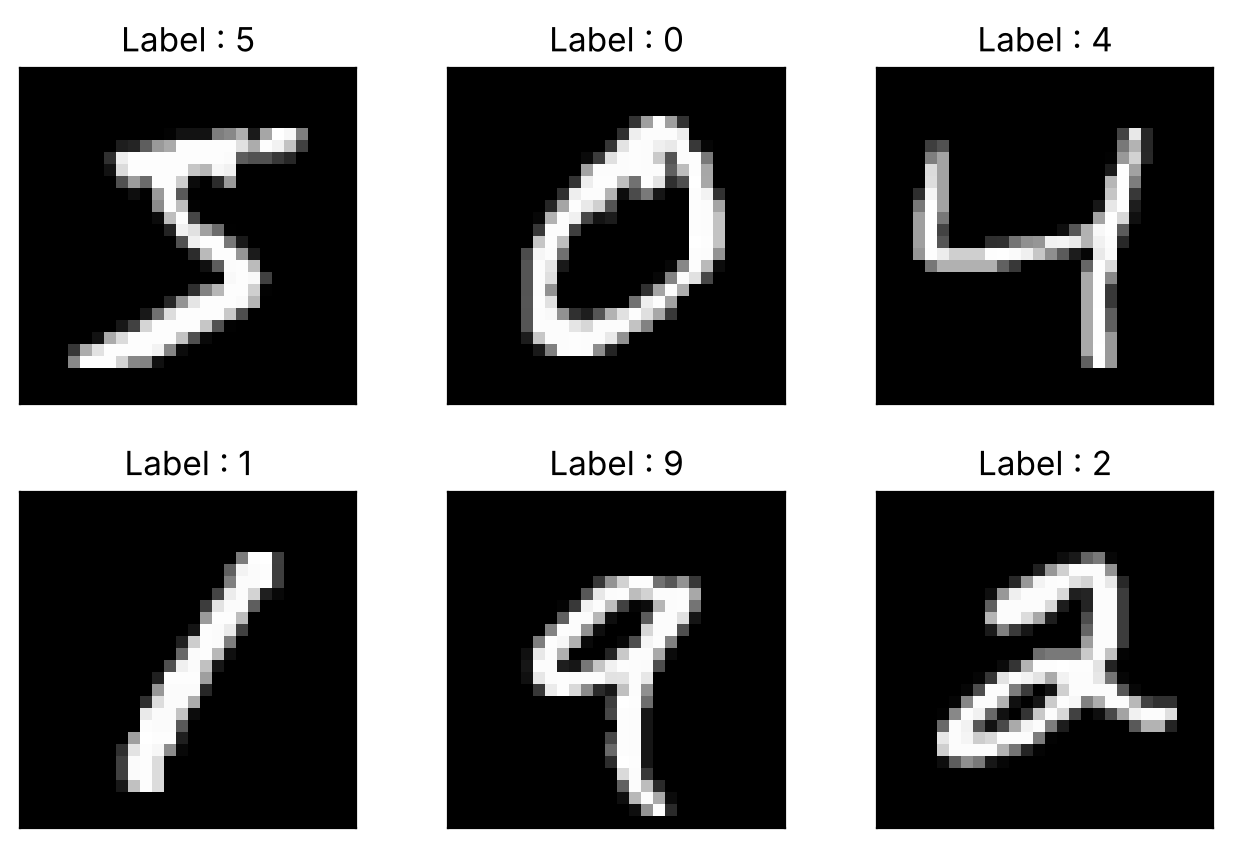

In [9]:
for i in range(6):
  plt.subplot(2,3,i+1)
  plt.tight_layout()
  plt.imshow(train.data[i], cmap='gray', interpolation='none')
  plt.title("Label : {}".format(train.targets[i]))
  plt.xticks([])
  plt.yticks([])
plt.show()


### Fully-Connected Layers

**Q3.** The following cell launches the training of the defined model. Take a moment to read it and understand the main blocks. Comment each block.

In [10]:
# ---------------------------------------------------------------------------------------------
# BLOC 1 - Early stopping : on s'arrête si le meilleur score (accuracy) date d'au moins `patience` epochs
# ---------------------------------------------------------------------------------------------
def early_stopping(scores: List[float], patience: int):
    last_idx = len(scores) - 1
    idx_val = scores.index(max(scores))
    if abs(last_idx - idx_val) >= patience:
        print("Early stopping ! Did not improve in {} iterations".format(patience))
        return True
    else:
        pass

# ---------------------------------------------------------------------------------------------
# Fonction d'entraînement complète (modèle, perte, optimiseur, données, nombre d'epochs, patience)
# ---------------------------------------------------------------------------------------------
def train_model(model, criterion, optimizer, dataloaders, device, num_epochs, patience,
                nb_train: int=60000, nb_test: int=10000, print_every: int=1):

    print('Model=%s, opt=%s(lr=%f), epochs=%d, device=%s\n' % \
        (type(model).__name__, type(optimizer).__name__,
        optimizer.param_groups[0]['lr'], num_epochs, device))

    # BLOC 2 - Initialisation : chrono, copie des meilleurs poids, dictionnaire `history` (courbes loss/accuracy)
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    history = {}
    history['loss'] = []
    history['val_loss'] = []
    history['acc'] = []
    history['val_acc'] = []
    best_epoch_acc_val = 0

    # BLOC 3 - Boucle sur les epochs (une epoch = un passage complet sur le jeu d'entraînement ET sur le jeu de test)
    for epoch in range(1, num_epochs+1):

        loss_train_tmp, loss_test_tmp = [], []
        running_corrects_train, running_corrects_test = 0, 0

        # BLOC 4 - Deux phases par epoch : 'train' (on apprend) puis 'test' (on évalue seulement)
        for phase in ['train', 'test']:
            if phase == 'train':
                model.train()   # mode entraînement : dropout actif
            else:
                model.eval()    # mode évaluation : dropout désactivé

            # BLOC 5 - Boucle sur les mini-batchs fournis par le DataLoader
            for idx, (inputs, labels) in enumerate(dataloaders[phase]):

                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()   # remise à zéro des gradients (PyTorch les accumule)

                # BLOC 6 - Passe avant (les gradients ne sont calculés qu'en phase 'train')
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs).to(device)   # logits
                    _, preds = torch.max(outputs, 1)       # classe prédite = indice du plus grand logit

                    loss = criterion(outputs, labels)      # perte (entropie croisée) du mini-batch

                    if phase == 'train':
                        loss.backward()    # rétropropagation : gradients de la perte
                        optimizer.step()   # mise à jour des paramètres (Adam)
                        loss_train_tmp.append(loss.item())
                        running_corrects_train += torch.sum(preds == labels.data).cpu()

                if phase == 'test':
                    loss_test_tmp.append(loss.item())
                    running_corrects_test += torch.sum(preds == labels.data).cpu()

        # BLOC 7 - Fin d'epoch : moyennes des pertes et accuracies (en %) ajoutées à `history`
        history['loss'].append(np.average(loss_train_tmp))
        history['val_loss'].append(np.average(loss_test_tmp))

        history['acc'].append((running_corrects_train / nb_train) * 100)
        history['val_acc'].append((running_corrects_test / nb_test) * 100)

        # BLOC 8 - On garde les poids de la meilleure epoch (selon l'accuracy sur le jeu de test), on affiche, et on teste les arrêts
        if history['val_acc'][-1] > best_epoch_acc_val:
            best_epoch_acc_val = history['val_acc'][-1]
            best_model_wts = copy.deepcopy(model.state_dict())
        if epoch % print_every == 0:
            print("Epoch {}/{}, train loss: {:.3f}, test loss: {:.3f}, train acc: {:.3f}, val acc: {:.3f}, best val acc: {:.3f}".format(
                epoch, num_epochs, history['loss'][-1], history['val_loss'][-1], history['acc'][-1], history['val_acc'][-1], max(history['val_acc'])))
        if history['val_acc'][-1] == 100:
            print("Early stoping ! Top score achieved")
            break
        if early_stopping(history['val_acc'], patience):
            break

    # BLOC 9 - Fin d'entraînement : durée, rechargement des MEILLEURS poids
    time_elapsed = time.time() - since

    print('Training complete in {:.0f}m {:.0f}s'.format(
        time_elapsed // 60, time_elapsed % 60))

    print("Best accuracy : {}".format(best_epoch_acc_val))

    model.load_state_dict(best_model_wts)

    model.eval()
    model.to(device)

    # BLOC 10 - Prédictions finales sur le jeu de test avec le meilleur modèle (pour la matrice de confusion)
    all_labels = []

    with torch.no_grad():
        for idx, (inputs, labels) in enumerate(dataloaders["test"]):
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs).to(device)
            all_labels.extend(list(labels.to("cpu").numpy()))
            if idx == 0:
                _, preds = torch.max(outputs, 1)
            else:
                _, tmp_preds = torch.max(outputs, 1)
                preds = torch.cat((preds, tmp_preds), axis=0)

    return model, history, preds, np.array(all_labels)

**Réponse Q3 (blocs de `train_model`, commentés dans le code ci-dessus).**

1. **Early stopping** : on arrête si la meilleure accuracy date d'au moins `patience` epochs (évite le surapprentissage et le temps perdu).
2. **Initialisation** : chrono, copie des meilleurs poids, dictionnaire `history` pour tracer les courbes.
3. **Boucle sur les epochs** : une epoch = un passage complet sur tout le jeu d'entraînement puis sur le jeu de test.
4. **Phases `train` / `test`** : `model.train()` active le dropout, `model.eval()` le désactive.
5. **Boucle sur les mini-batchs** fournis par le `DataLoader`.
6. **Passe avant** : calcul des logits, de la classe prédite (`argmax`) et de la perte ; le gradient n'est calculé qu'en phase `train` (`torch.set_grad_enabled`).
7. **Rétropropagation et mise à jour** (`zero_grad`, `loss.backward()`, `optimizer.step()`), seulement en phase `train`.
8. **Fin d'epoch** : moyennes de la perte et de l'accuracy, enregistrées dans `history`.
9. **Meilleur modèle** : on garde les poids de l'epoch où l'accuracy de test est la meilleure ; on affiche et on teste l'arrêt anticipé.
10. **Fin** : rechargement des meilleurs poids et prédictions finales (pour la matrice de confusion).

**Q4.** Implement a fully connected neural network consisting of three hidden layers and an output layer with 1024, 1024, 512, and 10 neurons, respectively.

Below is a summary of the operations:

**FULLY-CONNECTED -> ReLU -> DROPOUT -> FULLY-CONNECTED -> ReLU -> DROPOUT -> FULLY-CONNECTED -> ReLU -> DROPOUT -> FULLY-CONNECTED**



In [11]:
class FullyConnected(nn.Module):
    def __init__(self):
        super(FullyConnected, self).__init__()

        self.fc1 = nn.Linear(28*28, 1024)
        self.fc2 = nn.Linear(1024, 1024)
        self.fc3 = nn.Linear(1024, 512)
        self.fc4 = nn.Linear(512, 10)
        self.dropout = nn.Dropout(0.2)   # dropout probability (0.2, as for the CNN of Q7)

    def forward(self, x):
        x = x.view(-1, 28*28)  # Flatten the input
        x = self.dropout(F.relu(self.fc1(x)))   # FC -> ReLU -> DROPOUT
        x = self.dropout(F.relu(self.fc2(x)))   # FC -> ReLU -> DROPOUT
        x = self.dropout(F.relu(self.fc3(x)))   # FC -> ReLU -> DROPOUT
        out = self.fc4(x)                       # FC (logits: no softmax, CrossEntropyLoss applies it)
        return out


**Réponse Q4 (réseau entièrement connecté).**

Quatre couches `nn.Linear` : 784→1024, 1024→1024, 1024→512, 512→10. Après chacune des trois premières on applique **ReLU puis Dropout(0,2)** ; la dernière couche sort directement les **logits** (pas de softmax : `CrossEntropyLoss` l'intègre). L'image est d'abord aplatie (`x.view(-1, 28*28)`) car un MLP attend un vecteur : on perd la structure spatiale 2D, ce qui explique en partie ses moins bons résultats qu'un CNN.

**Q5.**: Compute the number of trainable parameters of the model (by hand and numerically).

**Réponse Q5 (nombre de paramètres du réseau dense).**

Pour une couche dense : (entrées × sorties) poids + sorties biais.

| Couche | Calcul | Paramètres |
|---|---|---|
| fc1 | 784×1024 + 1024 | 803 840 |
| fc2 | 1024×1024 + 1024 | 1 049 600 |
| fc3 | 1024×512 + 512 | 524 800 |
| fc4 | 512×10 + 10 | 5 130 |
| **Total** | | **2 383 370** |

La vérification numérique (cellule ci-dessus) donne bien **2 383 370** paramètres. ReLU, Dropout et l'aplatissement n'ont aucun paramètre.

In [12]:
# Q5 (numerically): trainable parameters of the fully-connected network, layer by layer
fc_model = FullyConnected()
for name, parameter in fc_model.named_parameters():
    print(f"{name:11s} shape = {str(tuple(parameter.shape)):13s} -> {parameter.numel():>9,d} parameters")
print(f"\nTotal trainable parameters : {count_parameters(fc_model):,}")

fc1.weight  shape = (1024, 784)   ->   802,816 parameters
fc1.bias    shape = (1024,)       ->     1,024 parameters
fc2.weight  shape = (1024, 1024)  -> 1,048,576 parameters
fc2.bias    shape = (1024,)       ->     1,024 parameters
fc3.weight  shape = (512, 1024)   ->   524,288 parameters
fc3.bias    shape = (512,)        ->       512 parameters
fc4.weight  shape = (10, 512)     ->     5,120 parameters
fc4.bias    shape = (10,)         ->        10 parameters

Total trainable parameters : 2,383,370


**Q6.**: In the following cell, you will complete the missing parts:

* Define the appropriate loss function for the problem we are addressing.  
* Use the Adam optimization algorithm with the previously defined learning rate, whose value is `'learning_rate'`.


In [13]:
model = FullyConnected()
criterion = nn.CrossEntropyLoss()                            # multi-class classification: softmax + negative log-likelihood
optimizer = optim.Adam(model.parameters(), lr=learning_rate)  # Adam with the learning rate defined above (0.001)

**Réponse Q6 (perte et optimiseur).**

- Perte : `nn.CrossEntropyLoss()` — problème de **classification multi-classes** (10 chiffres) ; elle combine softmax et log-vraisemblance négative et attend des logits et des étiquettes entières.
- Optimiseur : `optim.Adam(model.parameters(), lr=learning_rate)` avec `learning_rate = 0.001` (Adam adapte le pas par paramètre via moments d'ordre 1 et 2, comme vu dans le cours).

In [14]:
trained_model, history, preds, labels = train_model(model.to(device), criterion, optimizer, dataloaders, device, num_epochs, patience)

Model=FullyConnected, opt=Adam(lr=0.001000), epochs=5, device=cpu



Epoch 1/5, train loss: 0.468, test loss: 0.216, train acc: 84.892, val acc: 93.370, best val acc: 93.370


Epoch 2/5, train loss: 0.282, test loss: 0.131, train acc: 91.370, val acc: 96.080, best val acc: 96.080


Epoch 3/5, train loss: 0.241, test loss: 0.142, train acc: 92.525, val acc: 95.510, best val acc: 96.080


Epoch 4/5, train loss: 0.219, test loss: 0.105, train acc: 93.375, val acc: 96.700, best val acc: 96.700


Epoch 5/5, train loss: 0.200, test loss: 0.142, train acc: 93.998, val acc: 95.890, best val acc: 96.700
Training complete in 4m 57s
Best accuracy : 96.69999694824219


In [15]:
history_fc = history                          # keep the curves of the fully-connected network
record("FC 1024-1024-512", model, history_fc, kind="FC")
print(results["FC 1024-1024-512"])

{'params': 2383370, 'best_val_acc': 96.69999694824219, 'best_epoch': 4, 'final_train_acc': 93.99832916259766, 'final_val_acc': 95.88999938964844, 'final_train_loss': 0.20001143892643167, 'final_val_loss': 0.1416880864650011, 'epochs': 5, 'kind': 'FC'}


**Résultats du réseau dense (5 epochs, Adam, lr = 0,001, batch 64).**

La meilleure accuracy de test est **96,70 %** (epoch 4) ; à la dernière epoch : accuracy d'entraînement 94,00 %, test 95,89 %. La perte d'entraînement diminue régulièrement (0,468 → 0,200). L'accuracy de **test est supérieure à celle d'entraînement** : c'est normal ici car l'entraînement est mesuré avec dropout actif et sur des images augmentées (donc plus difficiles), alors que le test est propre et sans dropout. Les courbes de test sont un peu bruitées d'une epoch à l'autre (test : 93,4 → 96,1 → 95,5 → 96,7 → 95,9) ; le réseau n'a pas encore convergé après 5 epochs.

### Convolutional Neural Networks (CNNs)

**Q7.**: Implement a convolutional neural network consisting of two blocks, each including a convolutional layer, a non-linear ReLU activation function, a dropout layer, and a max-pooling layer. Then, add a fully connected layer with 128 neurons, followed by an output fully connected layer with 10 neurons.  

Below is a summary of the operations:

_CONV2D -> ReLU -> DROPOUT -> -> MAXPOOL -> CONV2D -> ReLU -> MAXPOOL -> DROPOUT -> FLATTEN -> FULLY-CONNECTED -> FULLY-CONNECTED_

You can find all the information related to the implementation of these layers on the following page:  
[https://pytorch.org/docs/stable/nn.html#convolution-layers](https://pytorch.org/docs/stable/nn.html#convolution-layers)


In [16]:
# Define a simple CNN model
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)    # (1, 28, 28)  -> (32, 26, 26)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)   # (32, 13, 13) -> (64, 11, 11)
        self.pool = nn.MaxPool2d(2)                     # divides height and width by 2 (floor): 26 -> 13 and 11 -> 5
        self.dropout = nn.Dropout(0.2)
        self.fc1 = nn.Linear(64 * 5 * 5, 128)           # flatten size = 64 x 5 x 5 = 1600
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Conv2d : 32 filtres, filtre 3x3,  ReLU
        x = F.relu(self.conv1(x))
        # Dropout :probability = 0.2
        x = self.dropout(x)
        # Max Pooling : filter of size 2
        x = self.pool(x)
        # Conv2d : 64 filtres, filter 3x3, ReLU
        x = F.relu(self.conv2(x))
        # Dropout :probability = 0.2
        x = self.dropout(x)
        # Max Pooling : filter of size 2
        x = self.pool(x)
        # Flatten
        x = torch.flatten(x, 1)
        # Fully-connected (flatten size,128),  ReLU
        x = F.relu(self.fc1(x))
        # Fully-connected (128,10)
        out = self.fc2(x)
        return out


**Réponse Q7 (CNN).**

Deux blocs `Conv2d(3×3) → ReLU → Dropout(0,2) → MaxPool(2)` : 1→32 filtres puis 32→64 filtres, suivis de `Flatten`, `Linear(1600, 128)` + ReLU et `Linear(128, 10)` (logits).

*Raisonnement (cours) :* la convolution exploite la **connectivité locale** et le **partage des poids** : un même filtre 3×3 est appliqué partout dans l'image (ce que fait réellement PyTorch est une corrélation croisée, sans retournement du filtre). Le max-pooling réduit la taille spatiale et apporte une petite invariance aux translations. Tailles : 28 → 26 (conv) → 13 (pool) → 11 (conv) → 5 (pool, le pooling arrondit à l'inférieur), d'où 64×5×5 = 1600 valeurs à l'entrée de la couche dense.

*Note :* le résumé de l'énoncé place le dropout du 2e bloc après le max-pooling dans une version et avant dans une autre ; j'ai choisi l'ordre cohérent des deux blocs (Conv → ReLU → Dropout → MaxPool).

**Q8.**: In the following cell, you will complete the missing parts:

* Instantiate the model
* Define the appropriate loss function for the problem we are addressing.  
* Use the Adam optimization algorithm with the previously defined learning rate, whose value is `'learning_rate'`.


In [17]:
model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

**Réponse Q8.**

`model = CNN()`, `criterion = nn.CrossEntropyLoss()` (classification à 10 classes) et `optimizer = optim.Adam(model.parameters(), lr=learning_rate)` — mêmes choix et mêmes justifications qu'en Q6.

In [18]:
total_params = 0
for _, parameter in model.named_parameters():
    if not parameter.requires_grad: continue
    param = parameter.numel()
    total_params += param
print("\nTotal Trainable Parameters : {}\n".format(total_params))


Total Trainable Parameters : 225034



**Q9.**: Compute the number of trainable parameters of the model (by hand).

In [19]:
# Q9 (check): shape of the tensor after every layer, for ONE 28x28 image
x = torch.zeros(1, 1, 28, 28)
cnn_check = CNN()
x = F.relu(cnn_check.conv1(x)); print("conv1 + ReLU :", tuple(x.shape))
x = cnn_check.pool(x);          print("max-pool     :", tuple(x.shape))
x = F.relu(cnn_check.conv2(x)); print("conv2 + ReLU :", tuple(x.shape))
x = cnn_check.pool(x);          print("max-pool     :", tuple(x.shape))
x = torch.flatten(x, 1);        print("flatten      :", tuple(x.shape))
print()
for name, parameter in cnn_check.named_parameters():
    print(f"{name:12s} shape = {str(tuple(parameter.shape)):16s} -> {parameter.numel():>8,d} parameters")

conv1 + ReLU : (1, 32, 26, 26)
max-pool     : (1, 32, 13, 13)
conv2 + ReLU : (1, 64, 11, 11)
max-pool     : (1, 64, 5, 5)
flatten      : (1, 1600)

conv1.weight shape = (32, 1, 3, 3)    ->      288 parameters
conv1.bias   shape = (32,)            ->       32 parameters
conv2.weight shape = (64, 32, 3, 3)   ->   18,432 parameters
conv2.bias   shape = (64,)            ->       64 parameters
fc1.weight   shape = (128, 1600)      ->  204,800 parameters
fc1.bias     shape = (128,)           ->      128 parameters
fc2.weight   shape = (10, 128)        ->    1,280 parameters
fc2.bias     shape = (10,)            ->       10 parameters


**Réponse Q9 (paramètres du CNN, à la main).**

Pour une convolution : (C_sortie × C_entrée × k × k) poids + C_sortie biais.

| Couche | Calcul | Paramètres |
|---|---|---|
| conv1 | 32×1×3×3 + 32 | 320 |
| conv2 | 64×32×3×3 + 64 | 18 496 |
| fc1 | 1600×128 + 128 | 204 928 |
| fc2 | 128×10 + 10 | 1 290 |
| **Total** | | **225 034** |

(Pooling, ReLU, dropout et flatten : 0 paramètre.) La vérification numérique donne exactement ces valeurs. Le CNN a **10 fois moins de paramètres** que le réseau dense (225 034 contre 2 383 370), grâce au partage des poids des filtres.

In the following cell, you will launch the training of the convolutional neural network defined above using 10 epochs and a batch size of 64.

In [20]:
trained_model, history, preds, labels = train_model(model.to(device), criterion, optimizer, dataloaders, device, num_epochs, patience)

Model=CNN, opt=Adam(lr=0.001000), epochs=5, device=cpu



Epoch 1/5, train loss: 0.333, test loss: 0.097, train acc: 89.418, val acc: 97.040, best val acc: 97.040


Epoch 2/5, train loss: 0.137, test loss: 0.069, train acc: 95.745, val acc: 97.790, best val acc: 97.790


Epoch 3/5, train loss: 0.106, test loss: 0.059, train acc: 96.703, val acc: 97.930, best val acc: 97.930


Epoch 4/5, train loss: 0.095, test loss: 0.057, train acc: 97.013, val acc: 98.320, best val acc: 98.320


Epoch 5/5, train loss: 0.083, test loss: 0.037, train acc: 97.367, val acc: 98.750, best val acc: 98.750
Training complete in 6m 40s
Best accuracy : 98.75


In [21]:
history_cnn = history                         # keep the curves of the CNN
record("CNN 32-64 / fc 128", model, history_cnn, kind="CNN")
print(results["CNN 32-64 / fc 128"])

{'params': 225034, 'best_val_acc': 98.75, 'best_epoch': 5, 'final_train_acc': 97.36666870117188, 'final_val_acc': 98.75, 'final_train_loss': 0.08277257630921234, 'final_val_loss': 0.037440256029367444, 'epochs': 5, 'kind': 'CNN'}


### Visualisation of the performances of the model on the training an test datasets

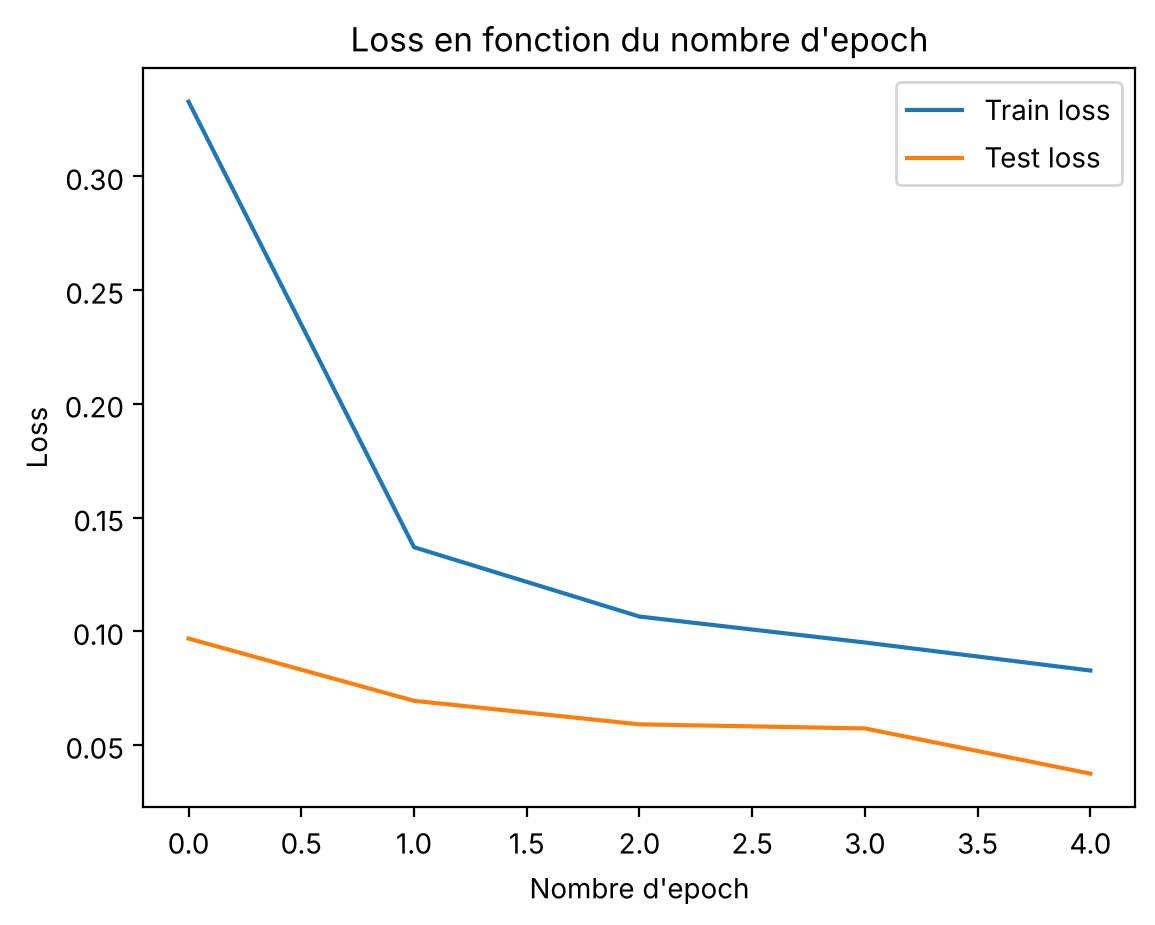

In [22]:
plt.plot(history['loss'], label="Train loss")
plt.plot(history['val_loss'], label="Test loss")
leg = plt.legend(loc="best")
plt.xlabel("Nombre d'epoch")
plt.ylabel("Loss")
plt.title("Loss en fonction du nombre d'epoch")
plt.show()

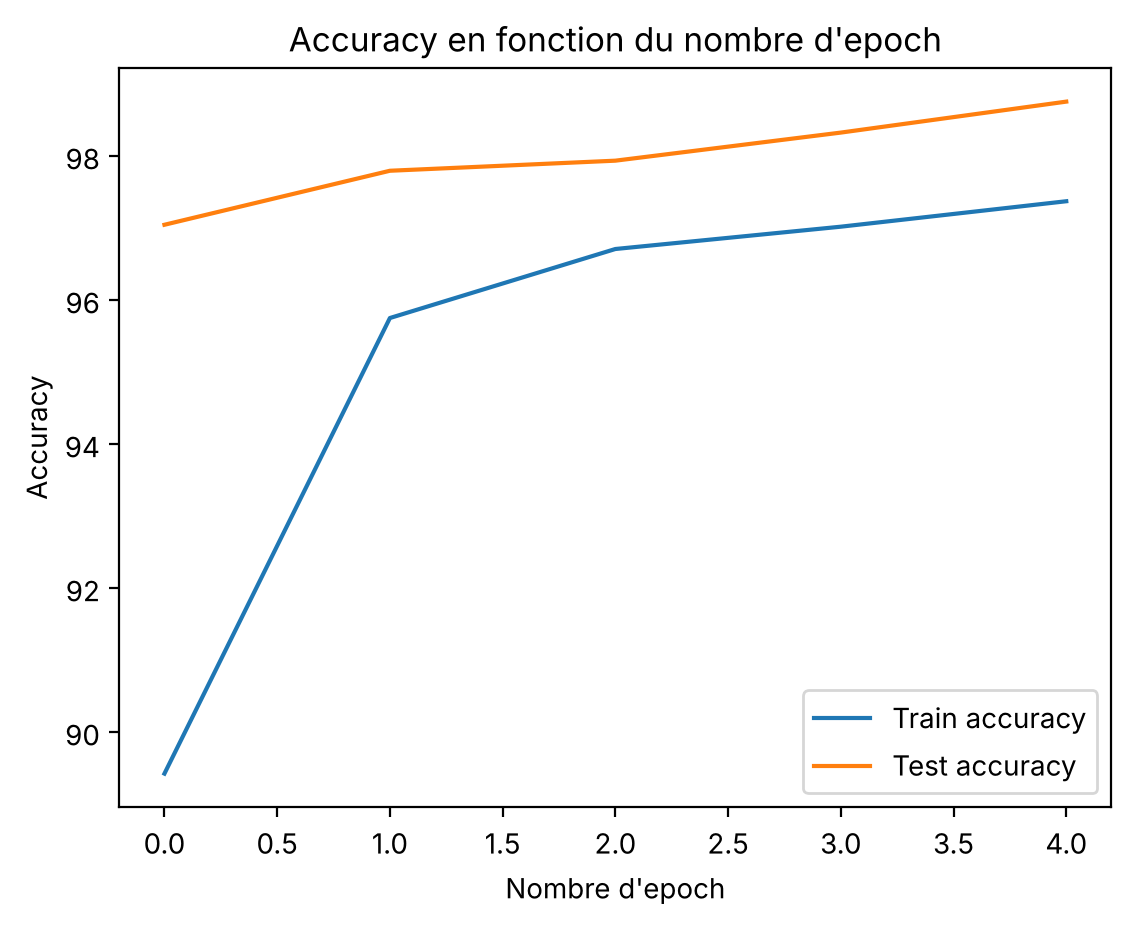

In [23]:
plt.plot(history['acc'], label="Train accuracy")
plt.plot(history['val_acc'], label="Test accuracy")
leg = plt.legend(loc="best")
plt.xlabel("Nombre d'epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy en fonction du nombre d'epoch")
plt.show()

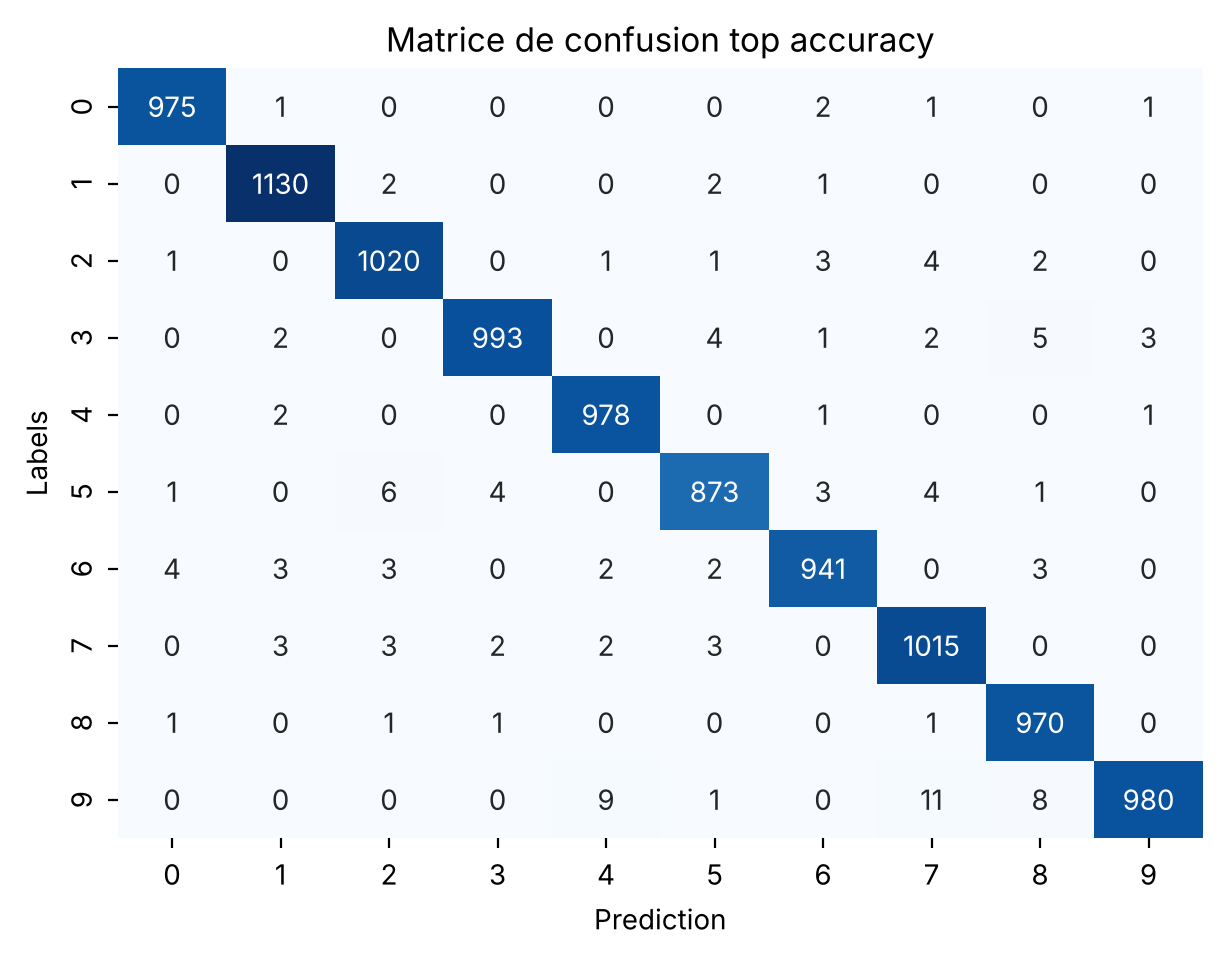

In [24]:
cm = confusion_matrix(labels, preds.to('cpu').numpy())
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues')
plt.xlabel('Prediction')
plt.ylabel('Labels')
plt.title("Matrice de confusion top accuracy")
plt.show()

**Résultats du CNN (5 epochs).**

Meilleure accuracy de test **98,75 %** (epoch 5), accuracy d'entraînement 97,37 %. La perte de test baisse à chaque epoch (0,097 → 0,037) et l'accuracy augmente encore : le modèle n'avait pas fini d'apprendre. Le CNN fait mieux que le réseau dense (98,75 % contre 96,70 %) avec 10 fois moins de paramètres.

**Q10.**:

* First, report the results obtained above.  
* Then, vary the number of hidden layers as well as the number of neurons in them, and record the accuracy for each tested architecture. Additionally, detail the calculation of the total number of parameters associated with each architecture.



In [25]:
# ---- Q10: architectures with a configurable number of hidden layers / neurons / filters
class MLP(nn.Module):
    """Fully-connected network with any list of hidden sizes. Hidden layer = FC -> ReLU -> Dropout(0.2)."""
    def __init__(self, hidden_sizes, p_drop=0.2):
        super().__init__()
        sizes = [28 * 28] + list(hidden_sizes) + [10]
        self.layers = nn.ModuleList([nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:])])
        self.dropout = nn.Dropout(p_drop)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        for layer in self.layers[:-1]:
            x = self.dropout(F.relu(layer(x)))
        return self.layers[-1](x)


class CNNVariant(nn.Module):
    """Blocks Conv(3x3) -> ReLU -> Dropout(0.2) -> MaxPool(2), then FC(fc) -> ReLU -> FC(10)."""
    def __init__(self, filters=(32, 64), fc=128, p_drop=0.2):
        super().__init__()
        chans = [1] + list(filters)
        self.convs = nn.ModuleList([nn.Conv2d(a, b, kernel_size=3) for a, b in zip(chans[:-1], chans[1:])])
        self.pool, self.dropout = nn.MaxPool2d(2), nn.Dropout(p_drop)
        size = 28
        for _ in filters:
            size = (size - 3 + 1) // 2          # 3x3 convolution without padding, then 2x2 max-pooling (floor)
        self.fc1 = nn.Linear(chans[-1] * size * size, fc)
        self.fc2 = nn.Linear(fc, 10)

    def forward(self, x):
        for conv in self.convs:
            x = self.pool(self.dropout(F.relu(conv(x))))
        x = torch.flatten(x, 1)
        return self.fc2(F.relu(self.fc1(x)))


def layer_details(model):
    """Hand-calculation of the parameters of every layer: inputs x outputs + biases."""
    rows = []
    for name, m in model.named_modules():
        if isinstance(m, nn.Linear):
            rows.append(f"{m.in_features}x{m.out_features}+{m.out_features}={m.weight.numel() + m.bias.numel():,}")
        elif isinstance(m, nn.Conv2d):
            k = m.kernel_size[0]
            rows.append(f"{m.out_channels}x{m.in_channels}x{k}x{k}+{m.out_channels}={m.weight.numel() + m.bias.numel():,}")
    return rows


def run_experiment(name, factory, **extra):
    """Train a fresh model (same seed, same optimizer, same number of epochs) and store its results."""
    seed_it_all()                                           # same seed for every experiment -> fair comparison
    model = factory().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    t0 = time.time()
    _, hist, _, _ = train_model(model, criterion, optimizer, dataloaders, device, num_epochs, patience)
    record(name, model, hist, seconds=time.time() - t0, details=layer_details(model), **extra)
    print(f"--> {name}: {count_parameters(model):,} parameters, best test accuracy = {results[name]['best_val_acc']:.2f} %\n")


In [26]:
# Fully-connected networks: vary the number of hidden layers and of neurons
fc_architectures = {
    "FC 2048-1024-512-256": [2048, 1024, 512, 256],   # 4 hidden layers, wider
    "FC 512-256": [512, 256],                          # 2 hidden layers
    "FC 256": [256],                                   # 1 hidden layer
    "FC 64": [64],                                     # 1 small hidden layer
    "FC 32-16": [32, 16],                              # 2 very small hidden layers
}
for name, hidden in fc_architectures.items():
    run_experiment(name, lambda h=hidden: MLP(h), kind="FC")

Model=MLP, opt=Adam(lr=0.001000), epochs=5, device=cpu



Epoch 1/5, train loss: 0.504, test loss: 0.195, train acc: 83.900, val acc: 94.130, best val acc: 94.130


Epoch 2/5, train loss: 0.298, test loss: 0.169, train acc: 91.182, val acc: 94.930, best val acc: 94.930


Epoch 3/5, train loss: 0.255, test loss: 0.118, train acc: 92.537, val acc: 96.550, best val acc: 96.550


Epoch 4/5, train loss: 0.232, test loss: 0.121, train acc: 93.182, val acc: 96.210, best val acc: 96.550


Epoch 5/5, train loss: 0.214, test loss: 0.123, train acc: 93.765, val acc: 96.220, best val acc: 96.550
Training complete in 7m 14s
Best accuracy : 96.55000305175781


... (21 outputs left out)

Epoch 3/5, train loss: 0.735, test loss: 0.373, train acc: 76.095, val acc: 87.800, best val acc: 87.800


Epoch 4/5, train loss: 0.700, test loss: 0.362, train acc: 77.188, val acc: 88.610, best val acc: 88.610


Epoch 5/5, train loss: 0.691, test loss: 0.357, train acc: 77.583, val acc: 88.270, best val acc: 88.610
Training complete in 2m 6s
Best accuracy : 88.61000061035156


--> FC 32-16: 25,818 parameters, best test accuracy = 88.61 %



In [27]:
# Convolutional networks: vary the number of filters, of blocks and the size of the dense layer
cnn_architectures = {
    "CNN 16-32 / fc 64": dict(filters=(16, 32), fc=64),
    "CNN 64-128 / fc 256": dict(filters=(64, 128), fc=256),
    "CNN 32 (1 block) / fc 128": dict(filters=(32,), fc=128),
}
for name, cfg in cnn_architectures.items():
    run_experiment(name, lambda c=cfg: CNNVariant(**c), kind="CNN")

Model=CNNVariant, opt=Adam(lr=0.001000), epochs=5, device=cpu



Epoch 1/5, train loss: 0.422, test loss: 0.147, train acc: 86.588, val acc: 95.800, best val acc: 95.800


Epoch 2/5, train loss: 0.184, test loss: 0.088, train acc: 94.333, val acc: 97.470, best val acc: 97.470


Epoch 3/5, train loss: 0.146, test loss: 0.070, train acc: 95.463, val acc: 97.900, best val acc: 97.900


Epoch 4/5, train loss: 0.121, test loss: 0.059, train acc: 96.235, val acc: 98.100, best val acc: 98.100


Epoch 5/5, train loss: 0.108, test loss: 0.056, train acc: 96.547, val acc: 98.300, best val acc: 98.300
Training complete in 3m 55s
Best accuracy : 98.29999542236328


... (9 outputs left out)

Epoch 3/5, train loss: 0.157, test loss: 0.095, train acc: 95.178, val acc: 96.950, best val acc: 96.950


Epoch 4/5, train loss: 0.135, test loss: 0.079, train acc: 95.837, val acc: 97.430, best val acc: 97.430


Epoch 5/5, train loss: 0.121, test loss: 0.072, train acc: 96.255, val acc: 97.820, best val acc: 97.820
Training complete in 6m 39s
Best accuracy : 97.81999969482422


--> CNN 32 (1 block) / fc 128: 693,962 parameters, best test accuracy = 97.82 %



Architecture                  #parameters  best test acc  last train acc  epoch
CNN 16-32 / fc 64                  56,714         98.30%          96.55%      5
CNN 32-64 / fc 128                225,034         98.75%          97.37%      5
CNN 32 (1 block) / fc 128         693,962         97.82%          96.25%      5
CNN 64-128 / fc 256               896,522         98.69%          97.75%      4
FC 32-16                           25,818         88.61%          77.58%      4
FC 64                              50,890         94.81%          88.99%      5
FC 256                            203,530         96.66%          93.06%      5
FC 512-256                        535,818         96.81%          93.90%      5
FC 1024-1024-512                2,383,370         96.70%          94.00%      4
FC 2048-1024-512-256            4,364,554         96.55%          93.76%      3


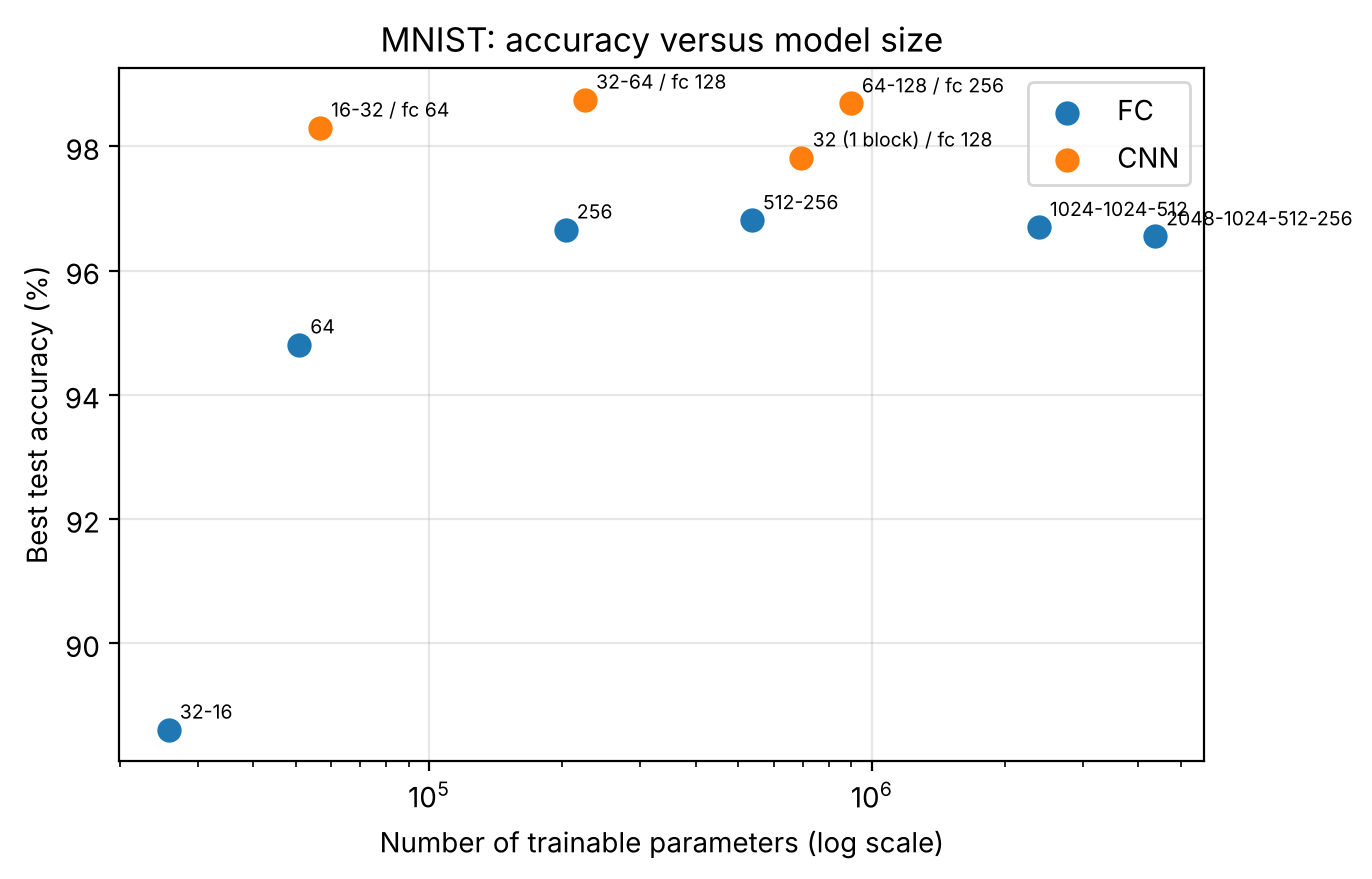

In [28]:
# Summary of all MNIST experiments (same budget: Adam, lr=0.001, 5 epochs, batch size 64)
print(f"{'Architecture':28s} {'#parameters':>12s} {'best test acc':>14s} {'last train acc':>15s}  {'epoch':>5s}")
for name, r in sorted(results.items(), key=lambda kv: (kv[1]['kind'], kv[1]['params'])):
    if r['kind'] not in ('FC', 'CNN'):
        continue
    print(f"{name:28s} {r['params']:>12,d} {r['best_val_acc']:>13.2f}% {r['final_train_acc']:>14.2f}%  {r['best_epoch']:>5d}")

plt.figure(figsize=(7, 4.5))
for kind, color in (('FC', 'tab:blue'), ('CNN', 'tab:orange')):
    pts = [(r['params'], r['best_val_acc'], n) for n, r in results.items() if r['kind'] == kind]
    plt.scatter([p[0] for p in pts], [p[1] for p in pts], c=color, label=kind, s=60)
    for p in pts:
        plt.annotate(p[2].split(' ', 1)[1], (p[0], p[1]), fontsize=7, xytext=(4, 4), textcoords='offset points')
plt.xscale('log'); plt.xlabel('Number of trainable parameters (log scale)'); plt.ylabel('Best test accuracy (%)')
plt.title('MNIST: accuracy versus model size'); plt.grid(alpha=0.3); plt.legend(); plt.show()

**Réponse Q10.**

*Résultats ci-dessus :* réseau dense 96,70 %, CNN 98,75 %.

*Variation des architectures* (même graine, Adam lr = 0,001, 5 epochs, batch 64 ; accuracy = meilleure accuracy sur le jeu de test) :

| Architecture | Calcul des paramètres | Total | Accuracy test |
|---|---|---|---|
| FC 32-16 | 784×32+32 = 25 120 ; 32×16+16 = 528 ; 16×10+10 = 170 | 25 818 | 88,61 % |
| FC 64 | 784×64+64 = 50 240 ; 64×10+10 = 650 | 50 890 | 94,81 % |
| FC 256 | 784×256+256 = 200 960 ; 256×10+10 = 2 570 | 203 530 | 96,66 % |
| FC 512-256 | 401 920 + 131 328 + 2 570 | 535 818 | 96,81 % |
| FC 1024-1024-512 (référence) | 803 840 + 1 049 600 + 524 800 + 5 130 | 2 383 370 | 96,70 % |
| FC 2048-1024-512-256 | 1 607 680 + 2 098 176 + 524 800 + 131 328 + 2 570 | 4 364 554 | 96,55 % |
| CNN 16-32 / fc 64 | 160 + 4 640 + (800×64+64 = 51 264) + 650 | 56 714 | 98,30 % |
| CNN 32-64 / fc 128 (référence) | 320 + 18 496 + 204 928 + 1 290 | 225 034 | 98,75 % |
| CNN 32 (1 bloc) / fc 128 | 320 + (5408×128+128 = 692 352) + 1 290 | 693 962 | 97,82 % |
| CNN 64-128 / fc 256 | 640 + 73 856 + (3200×256+256 = 819 456) + 2 570 | 896 522 | 98,69 % |

*Analyse :*
- Dans les réseaux denses, l'accuracy **augmente avec la capacité jusqu'à environ 200 000 paramètres** (88,6 % → 94,8 % → 96,7 %), puis **plafonne** (≈ 96,5-96,8 %) : ajouter des couches et des neurones n'améliore plus le résultat, il augmente seulement le temps de calcul (le plus gros réseau est le plus lent et n'est pas meilleur). Un réseau trop petit (32-16) **sous-apprend**.
- Les **CNN dominent à nombre de paramètres égal ou inférieur** : un CNN de 56 714 paramètres (98,30 %) bat tous les réseaux denses, même celui à 4,4 millions de paramètres. C'est la conséquence de la connectivité locale et du partage des poids.
- Le CNN à un seul bloc a plus de paramètres (693 962) car son vecteur aplati est plus grand (32×13×13 = 5408), mais il est moins bon (97,82 %) : **ce qui compte est la profondeur de l'extraction de caractéristiques, pas le nombre brut de paramètres**.
- Le CNN le plus large (896 522 paramètres) n'améliore pas la référence (98,69 % contre 98,75 %) : rendements décroissants.

*Limites :* une seule exécution par architecture et 5 epochs seulement ; les différences inférieures à ~0,3 point ne sont pas significatives. Le jeu de test sert aussi de validation (comme dans le TP).

## 2- Transfer Learning


---


---


Here, we will use the Transfer Learning technique to perform image classification. Indeed, it is rarely necessary to train a model from scratch, given the challenge of obtaining a sufficiently large dataset. Instead, it is common to use pre-trained models on large databases such as ImageNet.

There are two main procedures for Transfer Learning, as explained below:

* **Fine-tuning**: Instead of opting for random initialization, we initialize a pre-trained network for feature extraction, then add new fully connected layers.

* **Fixed feature extractor(Frozen Pre-Trained Model)**: We prevent the weights of the feature extraction part from updating, except for the newly added fully connected layers. Only the fully connected layer is trained.


**Q11.** Download the following dataset (https://download.pytorch.org/tutorial/hymenoptera_data.zip) and place it in a new folder named **data** in your drive.  

Here, we will focus on classifying ants and bees. To achieve this, we have a dataset consisting of **120 images** for each type of insect for training and **75 images** for validation/testing.


In [6]:
# Mount Google Drive when running on Google Colab (skipped when running elsewhere)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running on Google Colab: Google Drive is not mounted, the data will be stored in ./data")

Not running on Google Colab: Google Drive is not mounted, the data will be stored in ./data


Replace the following path with your path

In [7]:
if IN_COLAB:
    %cd /content/drive/'My Drive'/'Polytech'/'data'
else:
    # Outside Colab: download and unzip the hymenoptera dataset (ants / bees) in ./data
    import urllib.request, zipfile
    os.makedirs('data', exist_ok=True)
    os.chdir('data')
    if not os.path.isdir('hymenoptera_data'):
        urllib.request.urlretrieve('https://download.pytorch.org/tutorial/hymenoptera_data.zip', 'hymenoptera_data.zip')
        zipfile.ZipFile('hymenoptera_data.zip').extractall('.')
        os.remove('hymenoptera_data.zip')

In [8]:
! ls

MNIST  hymenoptera_data  hymenoptera_data.zip


In [9]:
import torch.backends.cudnn as cudnn
from torchvision import datasets, models, transforms
from PIL import Image
from tempfile import TemporaryDirectory

In [10]:
# Preprocessing and data augmentation

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

In [11]:
data_dir = 'hymenoptera_data'
dict_train_test ={'train':'train', 'test':'val'}
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[dict_train_test[x]], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['train', 'test']}
dataset_sizes = {x: len(image_datasets[dict_train_test[x]]) for x in ['train', 'test']}
class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

Visualizing a few datapoints

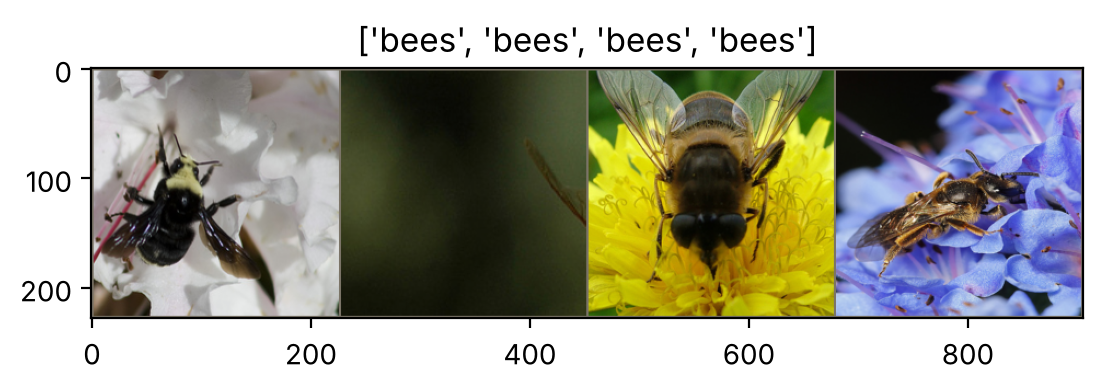

In [12]:
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)



inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

Function for visualizing predictions

In [13]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['test']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)


### Fine-tuning

**Q11.**: Set up a series of fully connected (FC) layers following the feature extraction part of the **ResNet-50** model.  

- The first layer will take as input the dimension of the last layer of **ResNet-18** and output **512 neurons**.  
- Then, there will be a second layer with **128 neurons**, followed by the output layer, which will have a number of neurons equal to the number of classes.  


In [14]:
seed_it_all()   # reproducible initialization of the new fully-connected head

model_ft = models.resnet50(weights='IMAGENET1K_V1') # ResNet-50 pretrained on ImageNet
print(model_ft)

num_ftrs = model_ft.fc.in_features # dimension of the last layer or  ResNet-50  for the feature extraction

model_ft.fc = nn.Sequential(
    nn.Linear(num_ftrs, 512),            # 2048 -> 512
    nn.ReLU(),
    nn.Linear(512, 128),                 # 512 -> 128
    nn.ReLU(),
    nn.Linear(128, len(class_names))     # 128 -> number of classes (2: ants / bees)
    )


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [15]:
# Number of trainable parameters of the fine-tuned network (all the layers are trained)
head = model_ft.fc
print(f"ResNet-50 feature extractor (everything except fc): {count_parameters(model_ft) - count_parameters(head):>11,d}")
print(f"New fully-connected head 2048-512-128-2           : {count_parameters(head):>11,d}")
print(f"Total trainable parameters                         : {count_parameters(model_ft):>11,d}")

ResNet-50 feature extractor (everything except fc):  23,508,032
New fully-connected head 2048-512-128-2           :   1,115,010
Total trainable parameters                         :  24,623,042


**Réponse Q11 (fine-tuning avec ResNet-50).**

On charge `resnet50` pré-entraîné sur ImageNet et on remplace sa dernière couche `fc` par `Linear(2048, 512) → ReLU → Linear(512, 128) → ReLU → Linear(128, 2)` (2048 est la dimension de sortie de l'extracteur de ResNet-50, 2 le nombre de classes : fourmis/abeilles). *Remarque :* l'énoncé parle de « ResNet-18 » pour la dimension d'entrée ; dans cette section le réseau est un ResNet-50, donc c'est `model_ft.fc.in_features` = 2048 qui est utilisé.

Paramètres : extracteur 23 508 032 + nouvelle tête 1 115 010 = **24 623 042**, tous entraînables.

*Raisonnement (cours) :* le **transfer learning** réutilise un réseau déjà entraîné sur un grand jeu (ImageNet) : ses premières couches détectent des motifs génériques (bords, textures) utiles pour d'autres tâches ; on ne remplace que la « tête » de classification. Avec seulement 244 images d'entraînement, entraîner un ResNet-50 de zéro serait impossible.

**Q12.**:  
* Define the appropriate loss function for the problem we are addressing.  
* Additionally, use the Adam optimization algorithm with a learning rate that you consider appropriate.  


In [16]:
model_ft = model_ft.to(device)
criterion = nn.CrossEntropyLoss()                          # 2-class classification (ants / bees)
optimizer_ft = optim.Adam(model_ft.parameters(), lr=1e-4)  # small learning rate: the pretrained weights must only be adjusted, not destroyed

**Réponse Q12.**

Perte `nn.CrossEntropyLoss()` (classification, ici à 2 classes) et `Adam` avec un **petit learning rate de 1e-4**. En fine-tuning on veut seulement **ajuster** les poids pré-entraînés : un pas trop grand les détruirait (c'est ce que confirme la Q15 : avec lr = 1e-3, l'accuracy tombe à 60 %).


In the following cell, you will launch the training of the convolutional neural network defined above using **25 epochs**. The batch size is set to **4** as defined earlier.  


In [17]:
trained_model, history, preds, labels = train_model(model_ft, criterion, optimizer_ft, dataloaders, device, 25, patience, dataset_sizes['train'], dataset_sizes['test'])

Model=ResNet, opt=Adam(lr=0.000100), epochs=25, device=cpu



Epoch 1/25, train loss: 0.541, test loss: 0.248, train acc: 73.770, val acc: 90.850, best val acc: 90.850


Epoch 2/25, train loss: 0.498, test loss: 0.504, train acc: 77.869, val acc: 79.085, best val acc: 90.850


Epoch 3/25, train loss: 0.431, test loss: 0.224, train acc: 80.738, val acc: 93.464, best val acc: 93.464


Epoch 4/25, train loss: 0.389, test loss: 0.727, train acc: 83.607, val acc: 79.085, best val acc: 93.464


Epoch 5/25, train loss: 0.491, test loss: 0.304, train acc: 77.049, val acc: 91.503, best val acc: 93.464


... (4 outputs left out)

Epoch 10/25, train loss: 0.333, test loss: 0.311, train acc: 87.295, val acc: 90.196, best val acc: 93.464


Epoch 11/25, train loss: 0.340, test loss: 0.425, train acc: 86.885, val acc: 80.392, best val acc: 93.464


Epoch 12/25, train loss: 0.266, test loss: 0.379, train acc: 90.164, val acc: 87.582, best val acc: 93.464


Epoch 13/25, train loss: 0.356, test loss: 0.301, train acc: 84.836, val acc: 90.850, best val acc: 93.464
Early stopping ! Did not improve in 10 iterations
Training complete in 11m 25s
Best accuracy : 93.46405029296875


In [18]:
history_ft, preds_ft, labels_ft = history, preds, labels   # keep the fine-tuning results (variables are overwritten below)
record("TL fine-tuning ResNet-50 (lr=1e-4)", model_ft, history_ft, kind="TL", scenario="fine-tuning", lr=1e-4)
print(results["TL fine-tuning ResNet-50 (lr=1e-4)"])

{'params': 24623042, 'best_val_acc': 93.46405029296875, 'best_epoch': 3, 'final_train_acc': 84.83606719970703, 'final_val_acc': 90.84967041015625, 'final_train_loss': 0.35592016767038676, 'final_val_loss': 0.3006037638212244, 'epochs': 13, 'kind': 'TL', 'scenario': 'fine-tuning', 'lr': 0.0001}


Visualize the predictions

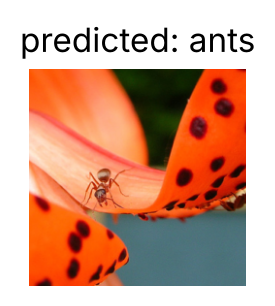

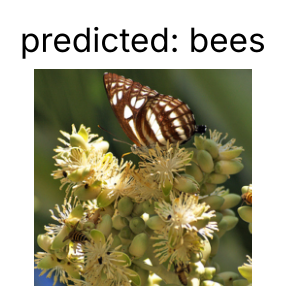

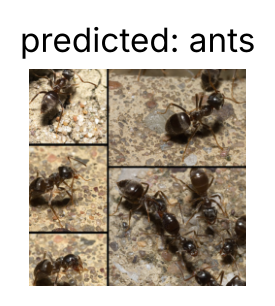

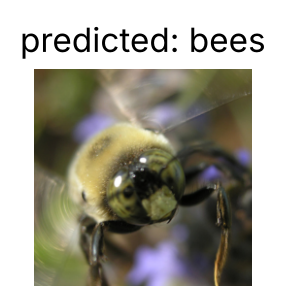

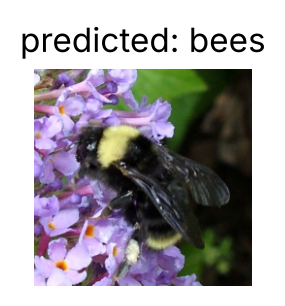

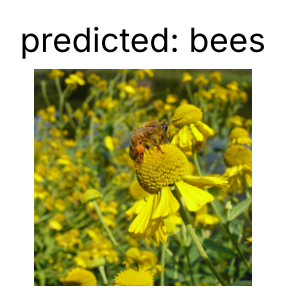

In [19]:
visualize_model(model_ft)

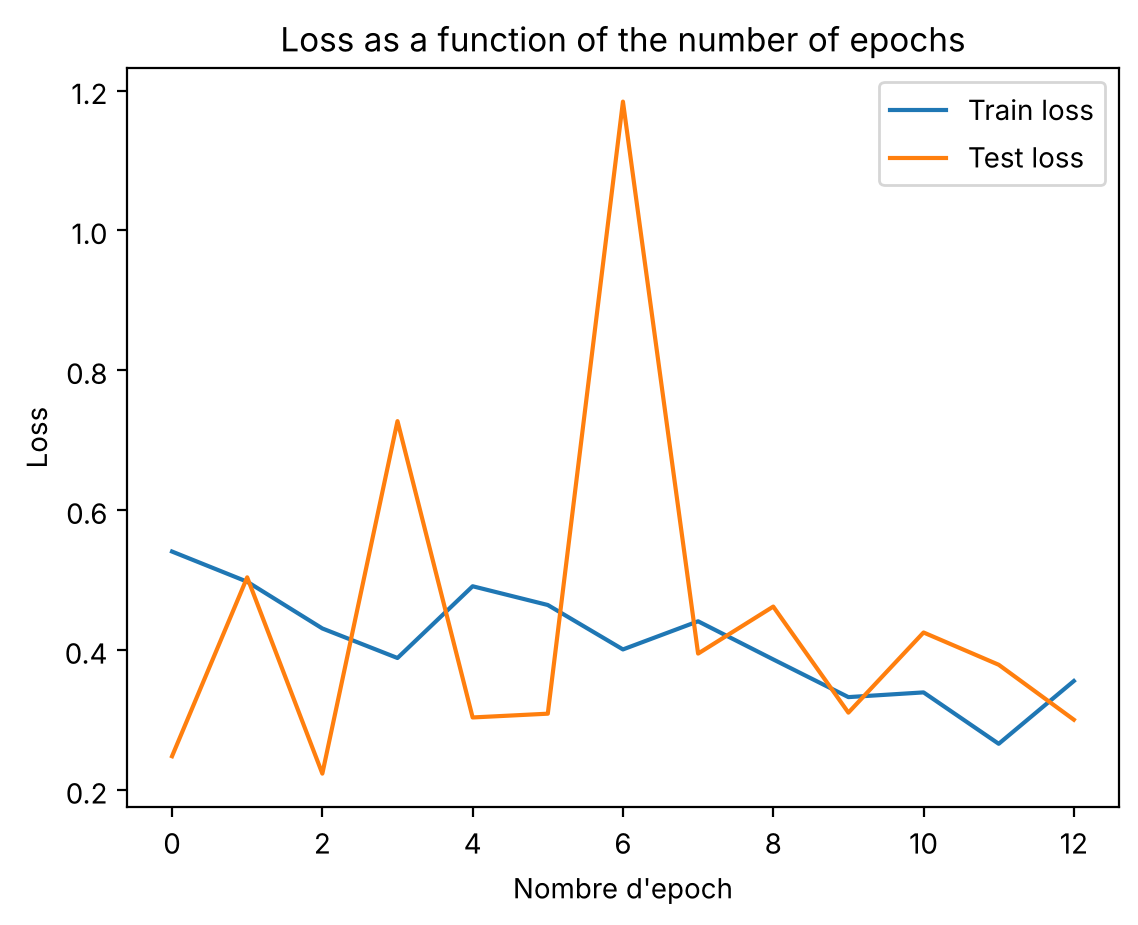

In [20]:
plt.plot(history['loss'], label="Train loss")
plt.plot(history['val_loss'], label="Test loss")
leg = plt.legend(loc="best")
plt.xlabel("Nombre d'epoch")
plt.ylabel("Loss")
plt.title("Loss as a function of the number of epochs")
plt.show()

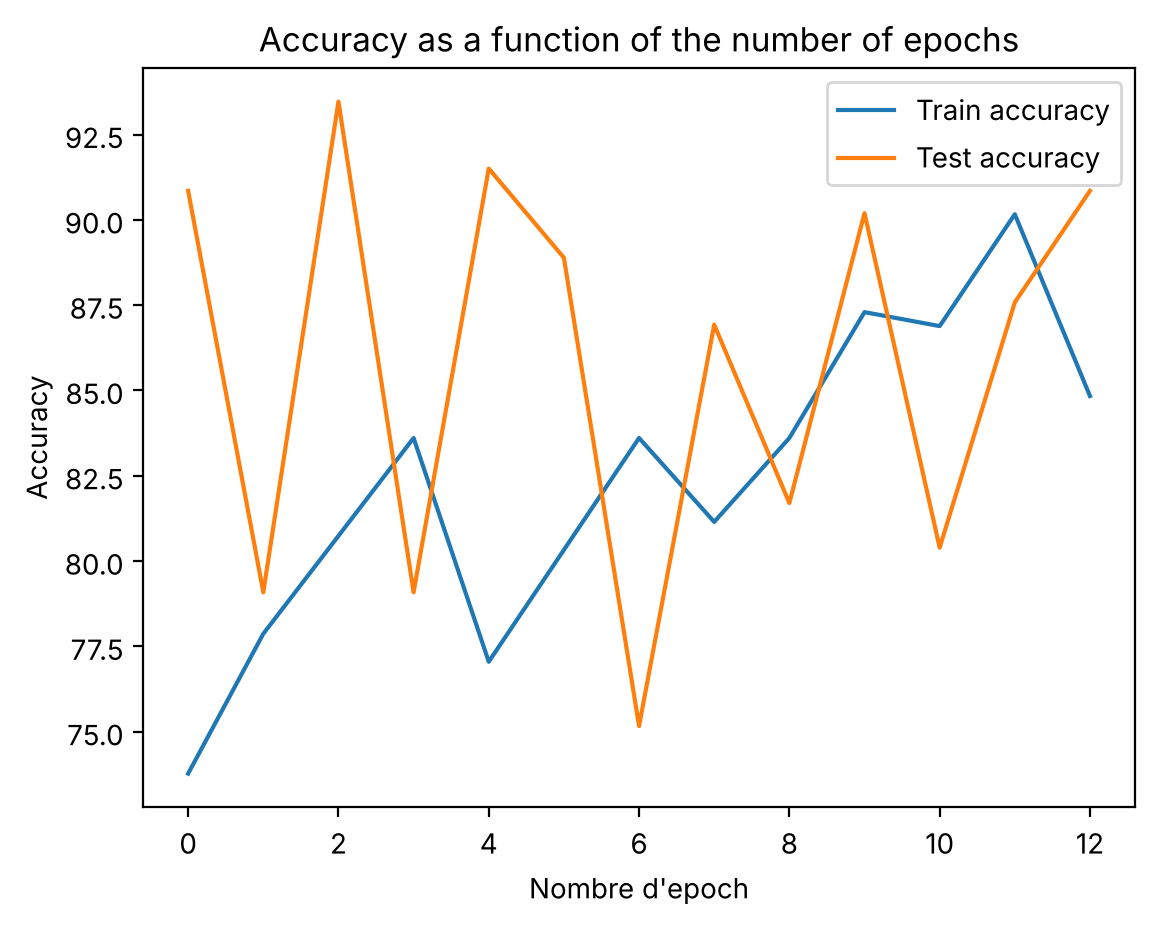

In [21]:
plt.plot(history['acc'], label="Train accuracy")
plt.plot(history['val_acc'], label="Test accuracy")
leg = plt.legend(loc="best")
plt.xlabel("Nombre d'epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy as a function of the number of epochs")
plt.show()

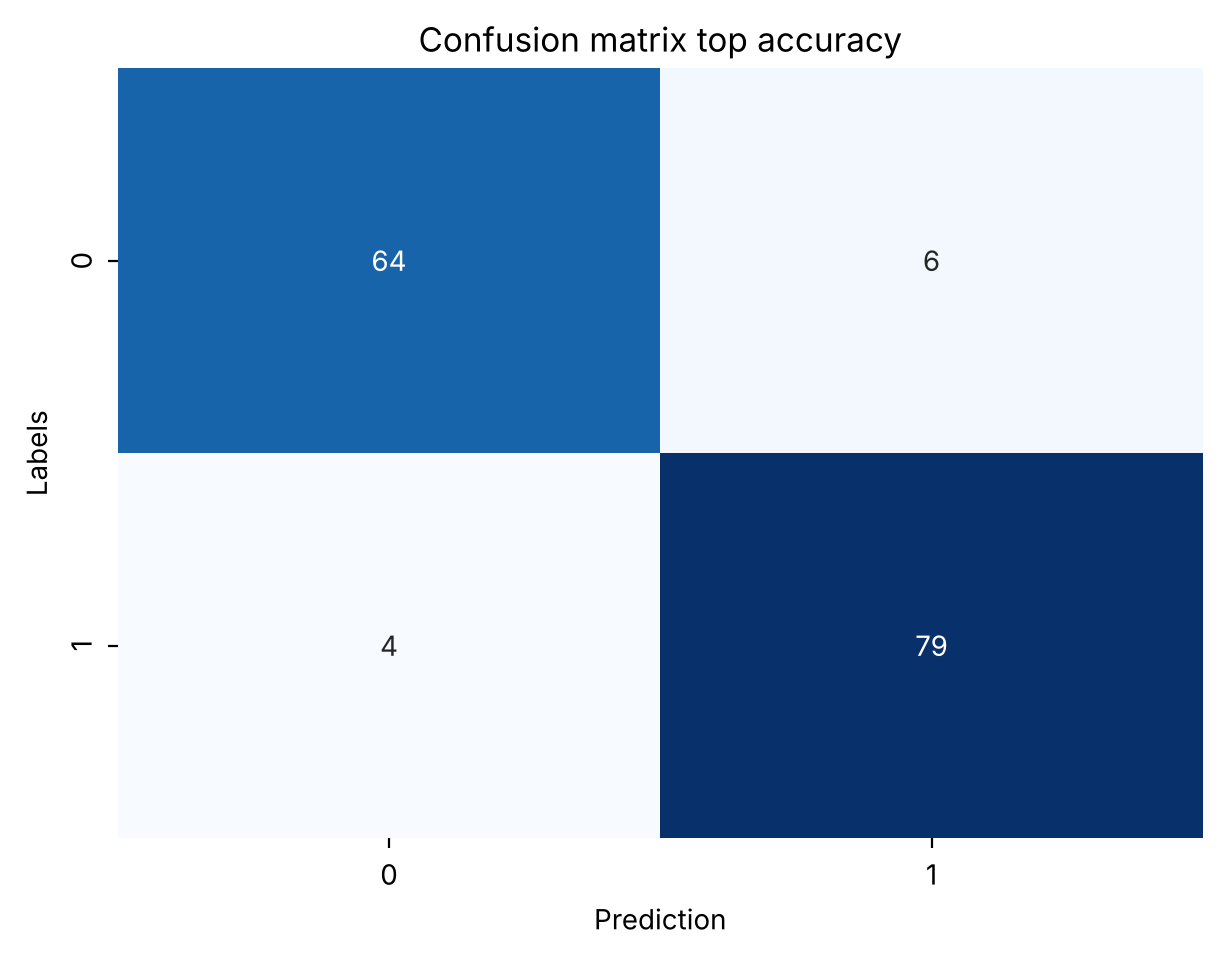

In [22]:
cm = confusion_matrix(labels, preds.to('cpu').numpy())
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues')
plt.xlabel('Prediction')
plt.ylabel('Labels')
plt.title("Confusion matrix top accuracy")
plt.show()

**Résultats du fine-tuning ResNet-50 (lr = 1e-4).**

Meilleure accuracy de test **93,46 %** (epoch 3, sur 153 images), puis l'early stopping a arrêté l'entraînement à l'epoch 13 : la perte de test ne s'améliore plus. L'accuracy d'entraînement finale (84,8 %) est inférieure à celle de test, car l'entraînement est mesuré avec augmentation et dropout éventuel. Le modèle est déjà très bon dès les premières epochs grâce aux caractéristiques ImageNet.

### Fixed feature extractor(Frozen Pre-Trained Model)

**Q13.**: You will set up a series of fully connected (FC) layers following the feature extraction part of the **ResNet-50** model.  

- The first layer will take as input the dimension of the last layer of **ResNet-18** and output **512 neurons**.  
- Then, there will be a second layer with **128 neurons**, followed by the output layer, which will have a number of neurons equal to the number of classes.  

In [23]:
seed_it_all()   # reproducible initialization of the new fully-connected head

model_conv = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Sequential(
    nn.Linear(num_ftrs, 512),            # 512 -> 512 (ResNet-18 outputs 512 features)
    nn.ReLU(),
    nn.Linear(512, 128),                 # 512 -> 128
    nn.ReLU(),
    nn.Linear(128, len(class_names)))    # 128 -> 2 classes

model_conv = model_conv.to(device)
criterion = nn.CrossEntropyLoss()
optimizer_conv = optim.Adam(model_conv.fc.parameters(), lr=1e-3)   # ONLY the new head is given to the optimizer

In [24]:
# Frozen feature extractor: only the new head is trainable
n_total = count_parameters(model_conv, trainable_only=False)
n_train = count_parameters(model_conv)
print(f"Total parameters of the network : {n_total:>11,d}")
print(f"Trainable (new head 512-512-128-2): {n_train:>9,d}  ({100 * n_train / n_total:.1f} % of the network)")
print(f"Frozen (ResNet-18 backbone)      : {n_total - n_train:>11,d}")

Total parameters of the network :  11,505,090
Trainable (new head 512-512-128-2):   328,578  (2.9 % of the network)
Frozen (ResNet-18 backbone)      :  11,176,512


**Réponse Q13 (extracteur de caractéristiques gelé).**

On charge `resnet18` pré-entraîné, on **gèle tous ses poids** (`requires_grad = False`) et on remplace `fc` par `Linear(512, 512) → ReLU → Linear(512, 128) → ReLU → Linear(128, 2)` (512 = sortie de ResNet-18). Seule cette nouvelle tête est donnée à l'optimiseur : `Adam(model_conv.fc.parameters(), lr=1e-3)`.

Paramètres : total 11 505 090 dont **328 578 entraînables** (2,9 %) et 11 176 512 gelés.

**Q14.** What is the difference with the previous approach ?

**Réponse Q14 (différence avec l'approche précédente).**

- **Fine-tuning (ResNet-50)** : *tous* les poids (24,6 M) sont mis à jour, avec un petit learning rate ; le réseau s'adapte entièrement à la nouvelle tâche, mais c'est **plus long** (ResNet-50 contre ResNet-18 : environ 2 fois plus de paramètres à mettre à jour et un réseau plus profond) et plus **fragile** (risque de surapprentissage avec peu d'images, et de destruction des poids pré-entraînés si le lr est trop grand).
- **Extracteur gelé (ResNet-18)** : seule la tête (328 578 paramètres) est entraînée ; l'extracteur ImageNet reste inchangé et sert de calculateur de caractéristiques. C'est **plus rapide, plus stable et moins sujet au surapprentissage** quand le jeu de données est petit et proche d'ImageNet, mais le réseau ne peut pas adapter ses caractéristiques à la tâche.

*Note :* la cellule d'entraînement d'origine entraînait par erreur `model_ft` avec `optimizer_ft`; elle a été corrigée pour entraîner `model_conv` avec `optimizer_conv`.

In the following cell, you will launch the training of the convolutional neural network defined above using **25 epochs**. The batch size is set to **4** as defined earlier.  


In [25]:
# NB: the original cell trained `model_ft` with `optimizer_ft` (the network of the previous section);
# here we train the frozen-backbone network `model_conv` with its own optimizer.
trained_model, history, preds, labels = train_model(model_conv, criterion, optimizer_conv, dataloaders, device, 25, patience, dataset_sizes['train'], dataset_sizes['test'])

Model=ResNet, opt=Adam(lr=0.001000), epochs=25, device=cpu



Epoch 1/25, train loss: 0.689, test loss: 0.519, train acc: 59.016, val acc: 64.706, best val acc: 64.706


Epoch 2/25, train loss: 0.559, test loss: 0.262, train acc: 70.082, val acc: 89.542, best val acc: 89.542


Epoch 3/25, train loss: 0.461, test loss: 0.237, train acc: 79.508, val acc: 94.771, best val acc: 94.771


Epoch 4/25, train loss: 0.403, test loss: 0.193, train acc: 81.557, val acc: 92.810, best val acc: 94.771


Epoch 5/25, train loss: 0.460, test loss: 0.277, train acc: 78.689, val acc: 94.118, best val acc: 94.771


... (8 outputs left out)

Epoch 14/25, train loss: 0.365, test loss: 0.189, train acc: 81.148, val acc: 93.464, best val acc: 96.078


Epoch 15/25, train loss: 0.359, test loss: 0.152, train acc: 83.197, val acc: 95.425, best val acc: 96.078


Epoch 16/25, train loss: 0.389, test loss: 0.178, train acc: 84.836, val acc: 94.771, best val acc: 96.078


Epoch 17/25, train loss: 0.440, test loss: 0.191, train acc: 75.000, val acc: 94.771, best val acc: 96.078
Early stopping ! Did not improve in 10 iterations
Training complete in 2m 56s
Best accuracy : 96.07843017578125


In [26]:
history_conv, preds_conv, labels_conv = history, preds, labels
record("TL frozen ResNet-18 (lr=1e-3)", model_conv, history_conv, kind="TL", scenario="frozen", lr=1e-3)
print(results["TL frozen ResNet-18 (lr=1e-3)"])

{'params': 328578, 'best_val_acc': 96.07843017578125, 'best_epoch': 7, 'final_train_acc': 75.0, 'final_val_acc': 94.771240234375, 'final_train_loss': 0.43952667774235615, 'final_val_loss': 0.19060166189685845, 'epochs': 17, 'kind': 'TL', 'scenario': 'frozen', 'lr': 0.001}


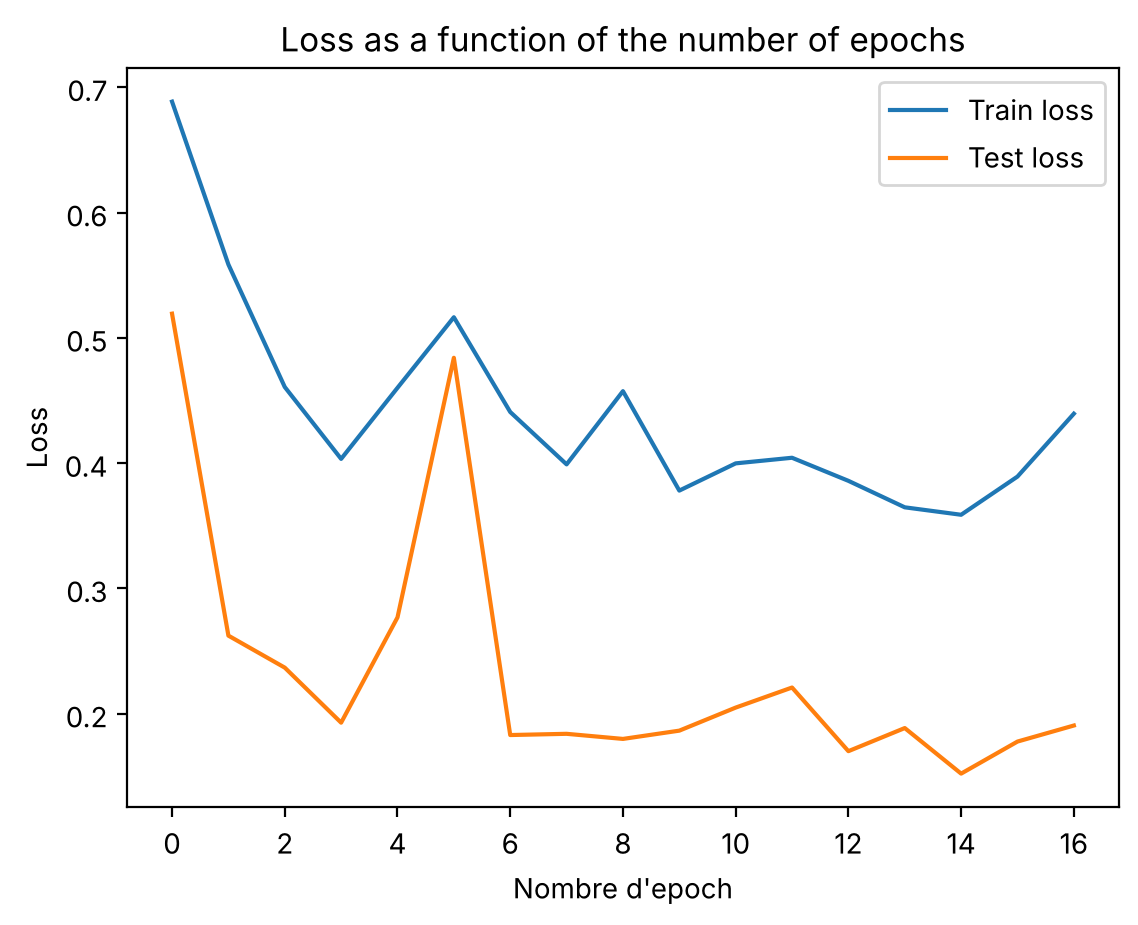

In [27]:
plt.plot(history['loss'], label="Train loss")
plt.plot(history['val_loss'], label="Test loss")
leg = plt.legend(loc="best")
plt.xlabel("Nombre d'epoch")
plt.ylabel("Loss")
plt.title("Loss as a function of the number of epochs")
plt.show()

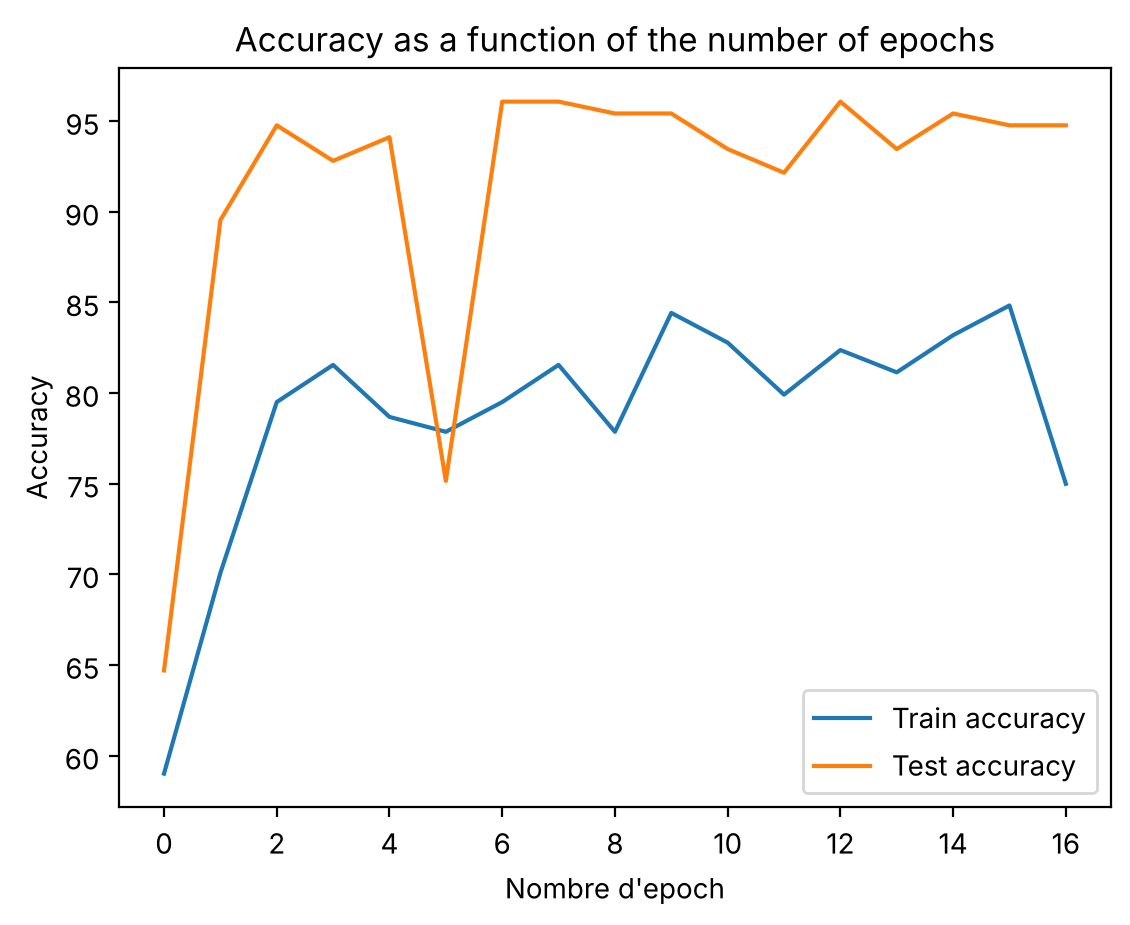

In [28]:
plt.plot(history['acc'], label="Train accuracy")
plt.plot(history['val_acc'], label="Test accuracy")
leg = plt.legend(loc="best")
plt.xlabel("Nombre d'epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy as a function of the number of epochs")
plt.show()

**Résultats de l'extracteur gelé (ResNet-18, lr = 1e-3).**

Meilleure accuracy de test **96,08 %** (epoch 7), arrêt anticipé à l'epoch 17. Avec seulement 2,9 % des paramètres entraînés, il fait **mieux** que le fine-tuning de ResNet-50 (93,46 %) : sur un jeu aussi petit (244 images), geler l'extracteur évite le surapprentissage. L'écart reste modeste et le test ne contient que 153 images (un point d'accuracy ≈ 1,5 image).

**Q15.**:  
* First, show the results associated with the two types of transfer learning.  
* Vary the learning rate for both scenarios. 

In [29]:
# ---- Q15: influence of the learning rate in both scenarios
EPOCHS_FT_VARIANT = 10       # fine-tuning ResNet-50 is slow on CPU: the extra learning rates are trained for 10 epochs
EPOCHS_FROZEN_VARIANT = 25   # frozen extractor: same budget as the main run (25 epochs)

def run_transfer(scenario, lr, epochs):
    """Fresh pretrained network (same seed) trained with Adam(lr) for `epochs` epochs."""
    seed_it_all()
    if scenario == "fine-tuning":
        m = models.resnet50(weights='IMAGENET1K_V1')
    else:
        m = models.resnet18(weights='IMAGENET1K_V1')
        for p in m.parameters():
            p.requires_grad = False
    m.fc = nn.Sequential(nn.Linear(m.fc.in_features, 512), nn.ReLU(), nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, len(class_names)))
    m = m.to(device)
    params = m.parameters() if scenario == "fine-tuning" else m.fc.parameters()
    _, hist, _, _ = train_model(m, nn.CrossEntropyLoss(), optim.Adam(params, lr=lr), dataloaders, device, epochs, patience,
                                dataset_sizes['train'], dataset_sizes['test'])
    record(f"TL {scenario} (lr={lr:g})", m, hist, kind="TL", scenario=scenario, lr=lr)
    return hist

tl_histories = {"fine-tuning": {1e-4: history_ft}, "frozen": {1e-3: history_conv}}   # main runs already done above
for lr in (1e-3, 1e-5):
    tl_histories["fine-tuning"][lr] = run_transfer("fine-tuning", lr, EPOCHS_FT_VARIANT)
for lr in (1e-2, 1e-4):
    tl_histories["frozen"][lr] = run_transfer("frozen", lr, EPOCHS_FROZEN_VARIANT)

Model=ResNet, opt=Adam(lr=0.001000), epochs=10, device=cpu



Epoch 1/10, train loss: 0.735, test loss: 1.579, train acc: 53.279, val acc: 54.248, best val acc: 54.248


Epoch 2/10, train loss: 0.701, test loss: 0.884, train acc: 50.000, val acc: 54.248, best val acc: 54.248


Epoch 3/10, train loss: 0.695, test loss: 0.687, train acc: 50.410, val acc: 54.248, best val acc: 54.248


Epoch 4/10, train loss: 0.693, test loss: 0.695, train acc: 51.230, val acc: 60.131, best val acc: 60.131


Epoch 5/10, train loss: 0.695, test loss: 0.685, train acc: 52.049, val acc: 58.170, best val acc: 60.131


... (47 outputs left out)

Epoch 13/25, train loss: 0.371, test loss: 0.184, train acc: 82.377, val acc: 94.771, best val acc: 96.078


Epoch 14/25, train loss: 0.348, test loss: 0.176, train acc: 82.787, val acc: 96.078, best val acc: 96.078


Epoch 15/25, train loss: 0.346, test loss: 0.161, train acc: 84.016, val acc: 96.078, best val acc: 96.078


Epoch 16/25, train loss: 0.378, test loss: 0.181, train acc: 83.197, val acc: 94.771, best val acc: 96.078
Early stopping ! Did not improve in 10 iterations
Training complete in 3m 5s
Best accuracy : 96.07843017578125


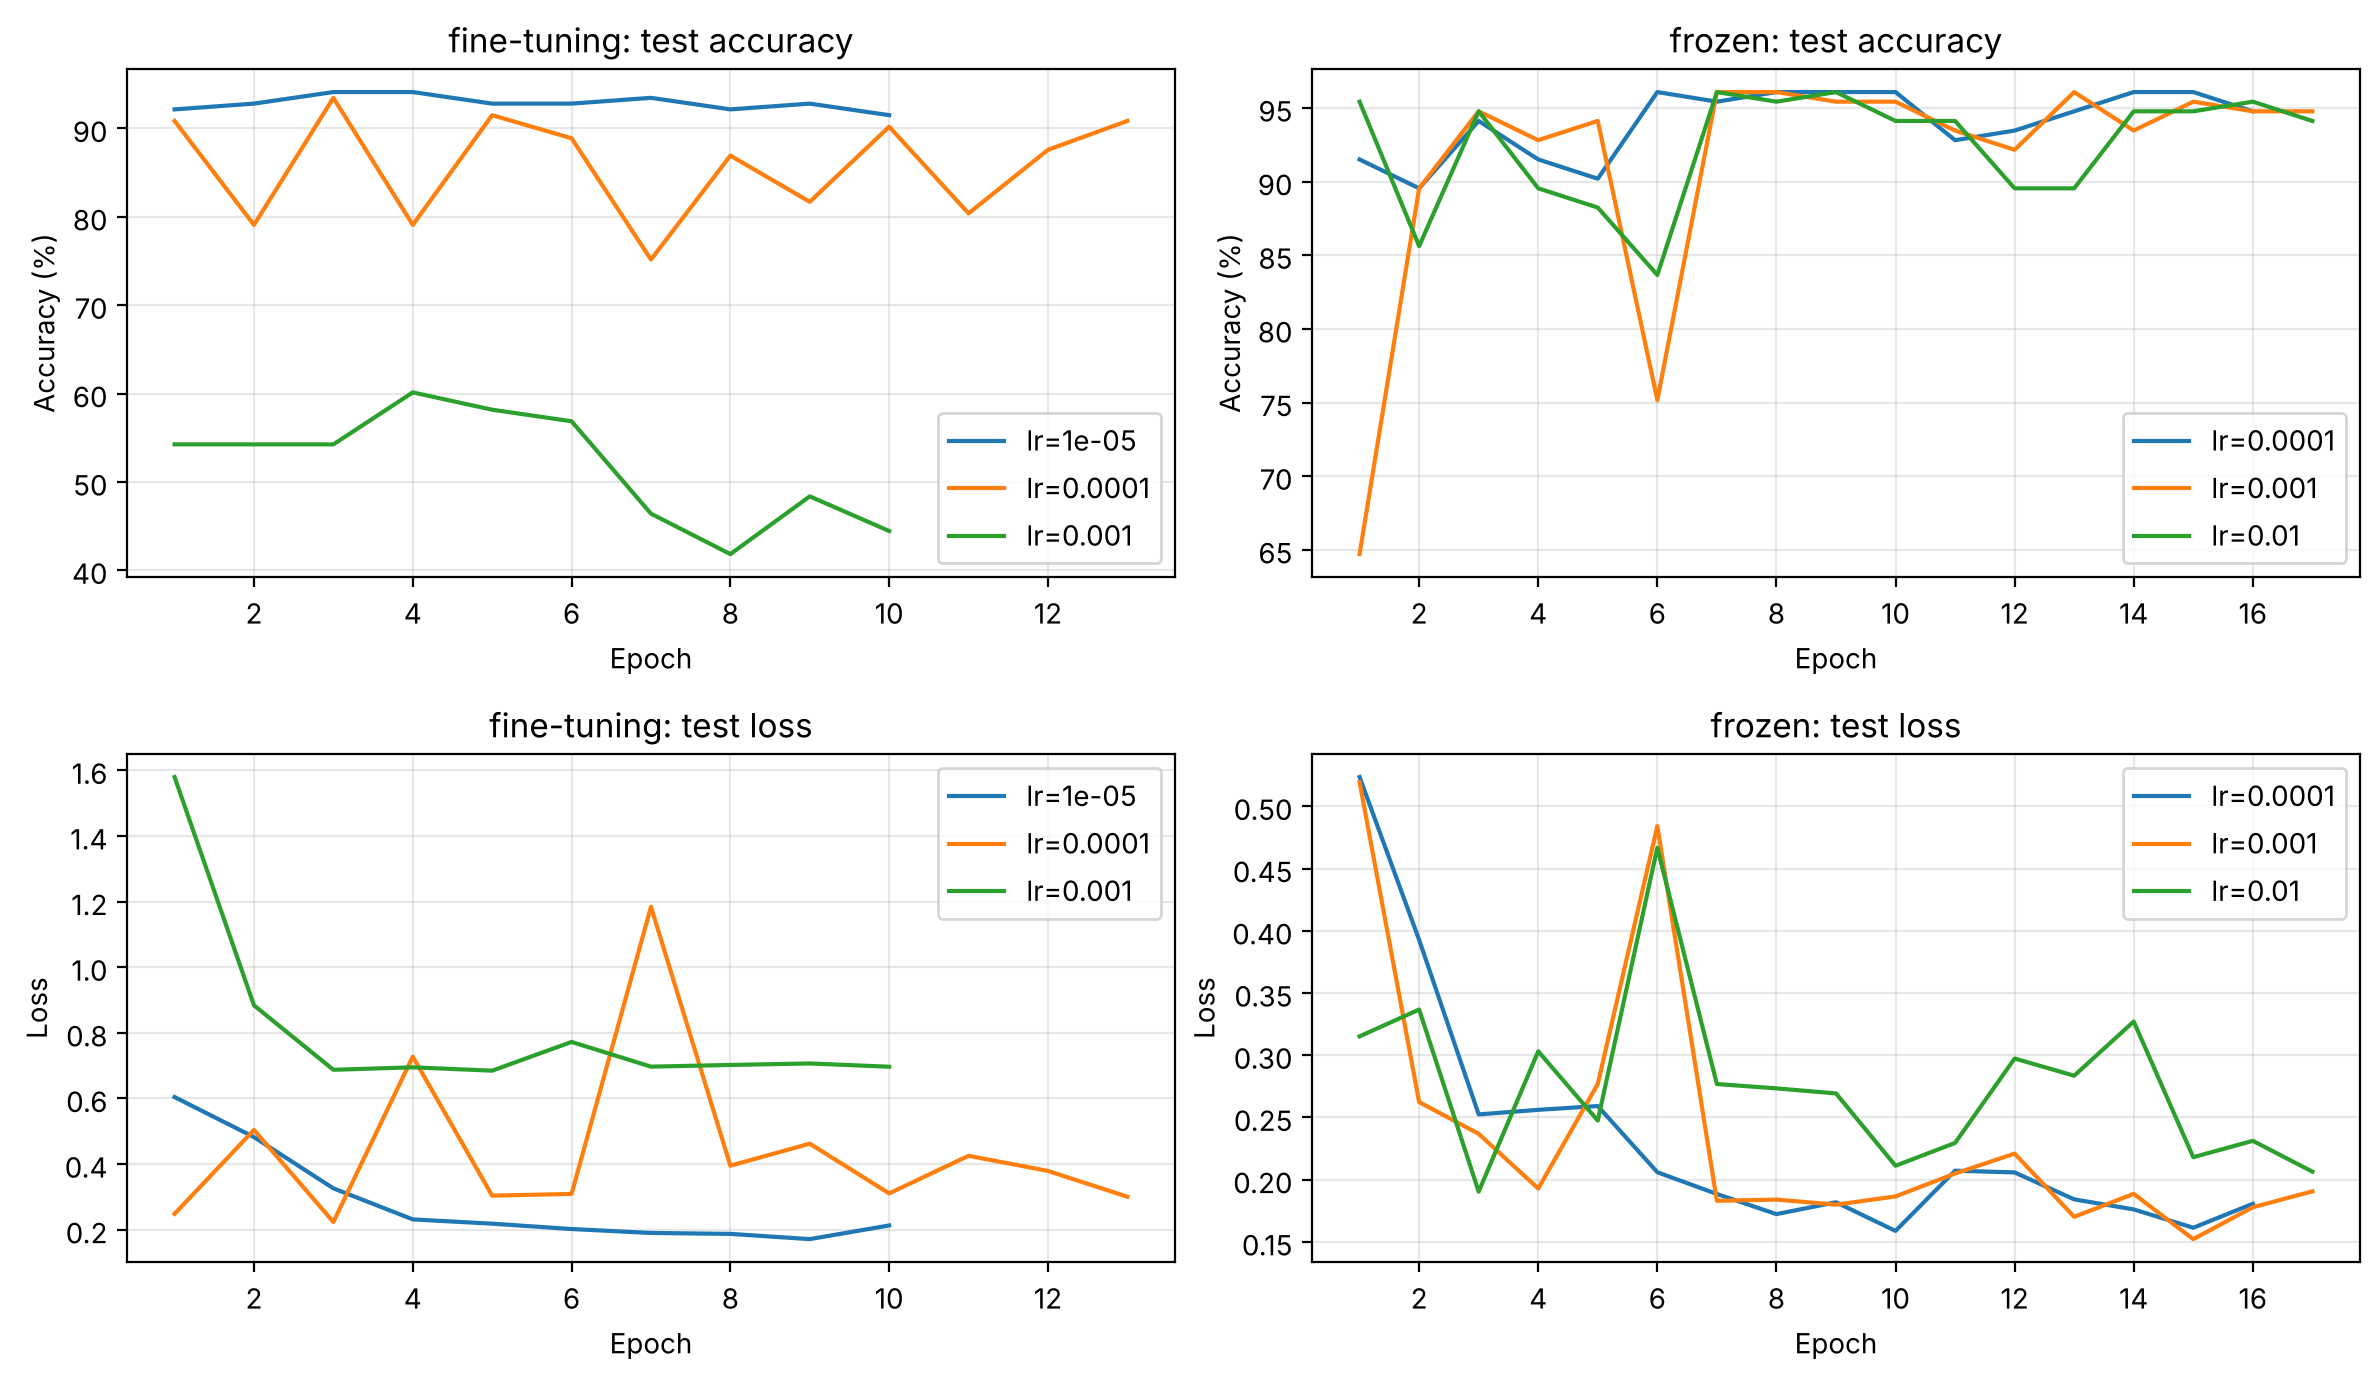

In [30]:
# Learning curves for every learning rate (left: fine-tuning ResNet-50, right: frozen ResNet-18)
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for col, scenario in enumerate(("fine-tuning", "frozen")):
    for lr, h in sorted(tl_histories[scenario].items()):
        axs[0, col].plot(range(1, len(h['val_acc']) + 1), [float(a) for a in h['val_acc']], label=f"lr={lr:g}")
        axs[1, col].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], label=f"lr={lr:g}")
    axs[0, col].set_title(f"{scenario}: test accuracy"); axs[1, col].set_title(f"{scenario}: test loss")
    axs[0, col].set_ylabel("Accuracy (%)"); axs[1, col].set_ylabel("Loss")
    for row in (0, 1):
        axs[row, col].set_xlabel("Epoch"); axs[row, col].grid(alpha=0.3); axs[row, col].legend()
plt.tight_layout(); plt.show()

In [31]:
# Summary table of the transfer-learning experiments
print(f"{'Scenario':22s} {'lr':>8s} {'epochs':>6s} {'trainable params':>17s} {'best test acc':>14s} {'best epoch':>11s} {'last train acc':>15s}")
for name, r in sorted(results.items(), key=lambda kv: (kv[1].get('scenario', ''), kv[1].get('lr', 0))):
    if r['kind'] != 'TL':
        continue
    print(f"{r['scenario']:22s} {r['lr']:>8g} {r['epochs']:>6d} {r['params']:>17,d} {r['best_val_acc']:>13.2f}% {r['best_epoch']:>11d} {r['final_train_acc']:>14.2f}%")

Scenario                     lr epochs  trainable params  best test acc  best epoch  last train acc
fine-tuning               1e-05     10        24,623,042         94.12%           3          88.93%
fine-tuning              0.0001     13        24,623,042         93.46%           3          84.84%
fine-tuning               0.001     10        24,623,042         60.13%           4          51.64%
frozen                   0.0001     16           328,578         96.08%           6          83.20%
frozen                    0.001     17           328,578         96.08%           7          75.00%
frozen                     0.01     17           328,578         96.08%           7          76.64%


**Réponse Q15 (influence du learning rate).**

| Scénario | lr | Epochs | Meilleure accuracy test |
|---|---|---|---|
| Fine-tuning ResNet-50 | 1e-5 | 10 | 94,12 % |
| Fine-tuning ResNet-50 | 1e-4 | 13 (arrêt anticipé) | 93,46 % |
| Fine-tuning ResNet-50 | 1e-3 | 10 | 60,13 % |
| Extracteur gelé ResNet-18 | 1e-4 | 16 (arrêt anticipé) | 96,08 % |
| Extracteur gelé ResNet-18 | 1e-3 | 17 (arrêt anticipé) | 96,08 % |
| Extracteur gelé ResNet-18 | 1e-2 | 17 (arrêt anticipé) | 96,08 % |

*Analyse :*
- **Fine-tuning : très sensible au learning rate.** À 1e-3 les gros pas détruisent les poids pré-entraînés (oubli catastrophique) : 60 % seulement. À 1e-4 et 1e-5, on conserve ce que le réseau sait et on obtient 93-94 %. Un petit lr est donc préférable quand on modifie tout le réseau.
- **Extracteur gelé : peu sensible** (96,08 % pour les trois valeurs, avec seulement 328 578 paramètres à ajuster et un extracteur qui reste intact) ; seule la vitesse de convergence change (meilleure epoch 6-7).
- Les accuracies d'entraînement sont plus basses que celles de test (augmentation + dropout dans l'entraînement).

*Limites :* les variantes de learning rate du fine-tuning ont été entraînées **10 epochs** (au lieu de 25) à cause du temps de calcul sur CPU ; le test (153 images) sert de validation ; une seule graine par configuration, donc les différences de 1-2 points entre 1e-4 et 1e-5 ne sont pas significatives.

**Conclusion.**

- Sur MNIST, les **CNN** surpassent les réseaux denses avec beaucoup moins de paramètres ; la capacité du réseau dense plafonne vers 200 000 paramètres.
- Sur le petit jeu fourmis/abeilles, le **transfer learning** est indispensable : le réseau gelé (96,08 %) et le fine-tuning avec un petit learning rate (93-94 %) donnent d'excellents résultats sans entraîner de zéro.
- Les expériences ont été exécutées sur **CPU** ; les chiffres exacts peuvent légèrement varier sur GPU ou avec une autre graine.